# Sistema de Decision Intelligence para la retención de clientes — Telco

**DataForge Consulting** · Proyecto final integrador · *Decision Intelligence & Business Analytics*
Escuela Colombiana de Ingeniería Julio Garavito · Docente: Juliana De Mier Medellín

**Equipo consultor:** Oscar Santiago Merino Suárez · Claudia Rocío Rodríguez Ortiz · Paula Andrea Gacha García · Daniel Felipe Pérez Pineda

> Este notebook es reproducible de principio a fin. Lee el archivo crudo `Data/WA_Fn-UseC_-Telco-Customer-Churn.csv`, audita su calidad, construye la tabla analítica `df_analitico`, calcula el sistema de métricas, ejecuta los análisis de desempeño, la priorización y la medición de impacto, y exporta las tablas que alimentan el informe y el modelo de Power BI. No modifica el archivo original.

**Contenido**

1. Contexto del negocio y Decision Canvas
2. Carga de datos
3. Unidad de análisis y granularidad
4. Auditoría de calidad de datos
5. Reglas de limpieza documentadas
6. Construcción de la tabla analítica `df_analitico`
7. Primeras agregaciones
8. Sistema de métricas: North Star, árbol y KPIs
9. Análisis de desempeño y drivers del churn
10. Priorización y medición de impacto (ROI y escenarios)
11. Plan de monitoreo y acción
12. Exportación del modelo para Power BI
13. Reflexión final

## 1. Contexto del negocio y Decision Canvas

**Cliente.** *Telco* es una operadora de telefonía e internet residencial. Los datos provienen del caso público de IBM, de modo que la compañía es ficticia. El corte analizado contiene 7,043 clientes con sus servicios contratados, tipo de contrato, forma de pago, cargos y una marca de abandono (*churn*).

**Situación.** En el período de corte abandonaron 1,869 clientes (26.5 %). Esos clientes pagaban USD 139 mil al mes, es decir, el 30.5 % del ingreso recurrente mensual (MRR). Como supuesto del caso, la Gerencia de Retención responde hoy con ofertas genéricas de descuento, sin priorizar a quién contactar ni medir el retorno de esas ofertas.

**Encargo a DataForge Consulting.** Diseñar un sistema analítico que apoye una decisión recurrente: **cada mes, qué clientes activos intervenir, con qué palanca y con cuánto presupuesto**, para reducir el MRR perdido por churn sin destruir valor (ARPU y margen).

> **Pregunta de decisión:** *¿Qué segmentos de clientes activos debe priorizar la Gerencia de Retención este mes, con qué palanca de retención y con qué retorno esperado, para reducir el MRR perdido por churn sin deteriorar el ARPU?*

### Decision Canvas (Plantilla 1 del enunciado)

| Componente | Respuesta de DataForge Consulting |
|---|---|
| **Problema organizacional** | Pérdida de clientes y de ingreso recurrente por churn (26.5 % de los clientes y 30.5 % del MRR en el corte). Las acciones de retención son genéricas y no se priorizan. |
| **Objetivo de negocio** | Reducir el MRR perdido por churn del 30.5 % al 25 % del MRR en dos trimestres, sin que el ARPU caiga más de 3 % (métrica de balance). |
| **Usuario de la decisión** | Gerente de Retención y Experiencia del Cliente (decide). Audiencia ejecutiva: Comité Directivo (VP Comercial y CFO). Ejecutan: Customer Success, Facturación y Producto. |
| **Decisión principal** | Cada mes, qué segmentos de clientes activos intervenir, con qué palanca de retención y con cuánto presupuesto. |
| **Alternativas de acción** | **A)** No intervenir (status quo). **B)** Descuento masivo a todos los clientes mes a mes. **C)** Programa focalizado por riesgo y valor, con una palanca por perfil: onboarding temprano, bundle de protección, pago automático o migración a contrato anual. **D)** Revisión estructural de la propuesta de valor de la fibra óptica (precio y calidad). |
| **Frecuencia de decisión** | Mensual para segmentos y presupuesto, seguimiento semanal de la ejecución y revisión trimestral de impacto con el comité. |
| **Métricas clave** | NSM % MRR retenido; tasa de churn; MRR perdido; churn temprano (0–6 meses); % de contratos a plazo; % de pago automático; adopción de protección; ARPU y ROI del programa (balance). |
| **Preguntas analíticas** | ¿Dónde se concentra el MRR perdido? ¿Qué factores explican el churn? ¿Qué clientes activos combinan alto riesgo y alto valor? ¿Qué palanca tiene mejor retorno esperado y bajo qué supuestos? |
| **Fuentes de datos** | Telco Customer Churn (IBM, vía Kaggle): un corte de 7,043 clientes y 21 variables. A futuro se requieren cortes mensuales, el CRM de contactos y ofertas, y los costos de servicio e incentivos. |
| **Unidad de análisis** | Cliente: una fila por cliente en el corte. |
| **Criterio de éxito** | % MRR perdido ≤ 25 % en dos trimestres; uplift de retención del piloto significativo frente al grupo control; ROI ≥ 0 en el escenario base; ARPU sin caídas mayores al 3 %. |
| **Riesgos o sesgos** | El corte no tiene fechas, así que no hay serie calendario. La ventana del churn es ambigua (mes o trimestre). Las comparaciones observacionales tienen sesgo de selección y la antigüedad tiene sesgo de supervivencia. Costos y efectividad de las palancas son supuestos no observados. |
| **Acción esperada** | Lanzar un piloto con grupo control sobre los clientes activos de riesgo alto, cada uno con su palanca asignada. Escalar solo si el uplift supera el MDE y el ROI es positivo. |
| **Monitoreo posterior** | Tablero mensual con semáforos (Plantilla 4), lectura del piloto a 30, 60 y 90 días y guardrails de ARPU y costo. |

## 2. Carga de datos

**Dataset:** *Telco Customer Churn*. Fuente: IBM Sample Data Sets, publicado en Kaggle por *blastchar* (<https://www.kaggle.com/datasets/blastchar/telco-customer-churn>).
**Por qué lo escogimos:** tiene un identificador de cliente, variables numéricas (cargos y antigüedad), variables categóricas accionables (contrato, servicio, método de pago) y una variable de resultado (churn). Eso permite conectar el problema de retención con métricas, segmentación y acciones concretas.

In [1]:
from math import erf, sqrt
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Rutas relativas a la raíz del repositorio (sirve si se ejecuta desde la raíz o desde notebooks/)
ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
RUTA_DATOS = ROOT / "Data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
DIR_FIG = ROOT / "outputs" / "figuras"
DIR_TAB = ROOT / "outputs" / "tablas"
DIR_PBI = ROOT / "powerbi" / "data"
for carpeta in (DIR_FIG, DIR_TAB, DIR_PBI):
    carpeta.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\Users\kimbo\Downloads\ProyectoFinalDIBA


In [2]:
# Paleta y estilo comunes a todas las figuras (los mismos colores del tema de Power BI)
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, GRIS_CLARO, GRILLA = "#898781", "#c3c2b7", "#e1e0d9"
CRITICO, SERIO, ALERTA, BIEN = "#d03b3b", "#ec835a", "#fab219", "#0ca30c"
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
RAMPA_AZUL = LinearSegmentedColormap.from_list("rampa_azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fuentes = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next((f for f in ["Segoe UI", "Arial", "DejaVu Sans"] if f in fuentes), "DejaVu Sans")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": FUENTE, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": GRIS_CLARO, "axes.labelcolor": TINTA_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})


def guardar(fig, nombre):
    # Guarda la figura en outputs/figuras para el informe y la presentación
    fig.savefig(DIR_FIG / f"{nombre}.png")
    plt.show()


def pct(v, dec=1):
    return f"{v * 100:.{dec}f} %"

In [3]:
df_raw = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df_raw.shape[0]:,} · Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 7,043 · Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Diccionario de las columnas originales**

| Columna | Significado | Valores |
|---|---|---|
| `customerID` | Identificador único del cliente | `7590-VHVEG` |
| `gender` | Género | Male / Female |
| `SeniorCitizen` | Adulto mayor (65+) | 1 / 0 (la única binaria codificada como número) |
| `Partner`, `Dependents` | Tiene pareja o dependientes | Yes / No |
| `tenure` | Meses que lleva el cliente con la compañía (antigüedad) | 0–72 |
| `PhoneService`, `MultipleLines` | Telefonía y líneas múltiples | Yes / No / No phone service |
| `InternetService` | Tipo de internet | DSL / Fiber optic / No |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Servicios adicionales sobre internet | Yes / No / No internet service |
| `Contract` | Tipo de contrato | Month-to-month / One year / Two year |
| `PaperlessBilling` | Factura electrónica | Yes / No |
| `PaymentMethod` | Método de pago | Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic) |
| `MonthlyCharges` | Cargo mensual actual (USD), que es el MRR del cliente | 18.25–118.75 |
| `TotalCharges` | Cargo acumulado durante toda la relación (USD) | Texto; se convierte a número |
| `Churn` | El cliente abandonó en el período de corte | Yes / No |

## 3. Unidad de análisis y granularidad

In [5]:
evidencia_granularidad = pd.Series({
    "Filas": len(df_raw),
    "customerID únicos": df_raw["customerID"].nunique(),
    "customerID nulos": int(df_raw["customerID"].isna().sum()),
    "¿Una fila = un cliente?": bool(df_raw["customerID"].is_unique),
    "Columnas de fecha calendario": 0,
    "Rango de tenure (meses)": f"{df_raw['tenure'].min()}–{df_raw['tenure'].max()}",
})
evidencia_granularidad.to_frame("Evidencia")

,Evidencia
Filas,7043
customerID únicos,7043
customerID nulos,0
¿Una fila = un cliente?,True
Columnas de fecha calendario,0
Rango de tenure (meses),0–72


**Mapa de granularidad**

| Elemento | Respuesta | Evidencia en datos |
|---|---|---|
| ¿Qué representa una fila? | Un cliente en un corte (*snapshot*). Es una **entidad**, no un evento ni una agregación. | 7,043 filas y 7,043 `customerID` únicos |
| Nivel de la base | Una sola tabla de nivel cliente. No es transaccional: no hay facturas ni eventos. | Una tabla, 21 columnas |
| Unidad de análisis original | Cliente | `customerID` es único |
| Unidad de análisis de la tabla analítica | **Cliente-corte**: una fila por cliente, preparada para sumar cortes mensuales futuros | Llave `customer_id` (+ `fecha_corte` cuando existan más cortes) |
| ID de evento | No existe (no hay transacciones) | — |
| ID de entidad | `customerID` | Sin nulos y sin duplicados |
| Fecha principal | **No hay fecha calendario.** La única variable temporal es `tenure` (meses de antigüedad), así que el análisis temporal se hace sobre el **ciclo de vida del cliente** y no sobre el calendario. | `tenure` entre 0 y 72 |
| Métricas que no deben salir de contar filas | El MRR es la suma de `MonthlyCharges`. El ARPU es una razón de sumas, no un promedio de promedios. Las tasas necesitan un numerador y un denominador explícitos. `TotalCharges` es un acumulado histórico, no el ingreso del período. | — |
| Riesgo de doble conteo | Al agregar cortes mensuales (cliente-mes), contar filas duplicaría clientes, así que se debe contar `customer_id` distinto por corte. Al promediar tasas de segmentos sin ponderar se sesga el churn total. | — |

## 4. Auditoría de calidad de datos

Se revisan las dimensiones de calidad vistas en la Sesión 3: completitud, unicidad, validez, consistencia, integridad de llaves, temporalidad y reglas de negocio. Cada hallazgo se registra con su severidad, la regla propuesta y la métrica afectada (Plantilla 3 del enunciado).

In [6]:
COLS_TEXTO = [c for c in df_raw.columns if not pd.api.types.is_numeric_dtype(df_raw[c])]

# 4.1 Nulos explícitos y "nulos ocultos" (cadenas vacías o solo espacios)
nulos = pd.DataFrame({
    "nulos_explicitos": df_raw.isna().sum(),
    "vacios_o_espacios": pd.Series({c: int((df_raw[c].astype(str).str.strip() == "").sum()) for c in df_raw.columns}),
})
nulos["pct_filas"] = (nulos["nulos_explicitos"] + nulos["vacios_o_espacios"]) / len(df_raw) * 100
nulos[(nulos["nulos_explicitos"] + nulos["vacios_o_espacios"]) > 0]

,nulos_explicitos,vacios_o_espacios,pct_filas
TotalCharges,0,11,0.1562


In [7]:
# 4.2 Duplicados exactos, por llave y por perfil (todas las columnas menos el ID)
duplicados = pd.Series({
    "Duplicados exactos": int(df_raw.duplicated().sum()),
    "Duplicados por llave (customerID)": int(df_raw.duplicated(subset=["customerID"]).sum()),
    "Filas con perfil idéntico a otra (sin el ID)": int(df_raw.drop(columns="customerID").duplicated().sum()),
})
duplicados.to_frame("Conteo")

,Conteo
Duplicados exactos,0
Duplicados por llave (customerID),0
Filas con perfil idéntico a otra (sin el ID),22


In [8]:
# 4.3 Tipos de dato: TotalCharges llega como texto por las cadenas vacías
total_num = pd.to_numeric(df_raw["TotalCharges"].str.strip(), errors="coerce")
print("dtype original de TotalCharges:", df_raw["TotalCharges"].dtype)
print("Valores no convertibles a número:", int(total_num.isna().sum()))
print("tenure de esos registros:", sorted(df_raw.loc[total_num.isna(), "tenure"].unique().tolist()))
print("SeniorCitizen está codificada como", sorted(df_raw["SeniorCitizen"].unique().tolist()), "mientras las demás binarias usan Yes/No")

dtype original de TotalCharges: str
Valores no convertibles a número: 11
tenure de esos registros: [0]
SeniorCitizen está codificada como [0, 1] mientras las demás binarias usan Yes/No


In [9]:
# 4.4 Categorías: dominios de valores, espacios sobrantes y variantes de mayúsculas o minúsculas
dominios = []
for c in COLS_TEXTO:
    if c in ("customerID", "TotalCharges"):
        continue
    valores = df_raw[c].astype(str)
    dominios.append({
        "columna": c,
        "categorias": ", ".join(sorted(valores.unique())),
        "n_categorias": valores.nunique(),
        "con_espacios_sobrantes": int((valores != valores.str.strip()).sum()),
        "variantes_mayus_minus": valores.nunique() - valores.str.lower().str.strip().nunique(),
    })
pd.DataFrame(dominios)

,columna,categorias,n_categorias,con_espacios_sobrantes,variantes_mayus_minus
0,gender,"Female, Male",2,0,0
1,Partner,"No, Yes",2,0,0
2,Dependents,"No, Yes",2,0,0
3,PhoneService,"No, Yes",2,0,0
4,MultipleLines,"No, No phone service, Yes",3,0,0
5,InternetService,"DSL, Fiber optic, No",3,0,0
6,OnlineSecurity,"No, No internet service, Yes",3,0,0
7,OnlineBackup,"No, No internet service, Yes",3,0,0
8,DeviceProtection,"No, No internet service, Yes",3,0,0
9,TechSupport,"No, No internet service, Yes",3,0,0


In [10]:
# 4.5 Rangos numéricos y formato de la llave
print(df_raw[["tenure", "MonthlyCharges"]].describe().T[["min", "max", "mean"]])
print("TotalCharges (numérico): min", total_num.min(), "· max", total_num.max())
print("Valores negativos:", int((df_raw[["tenure", "MonthlyCharges"]] < 0).sum().sum() + (total_num < 0).sum()))
formato_id = df_raw["customerID"].str.match(r"^\d{4}-[A-Z]{5}$")
print("customerID con formato válido (4 dígitos-5 letras):", int(formato_id.sum()), "de", len(df_raw))

                   min      max    mean
tenure          0.0000  72.0000 32.3711
MonthlyCharges 18.2500 118.7500 64.7617
TotalCharges (numérico): min 18.8 · max 8684.8
Valores negativos: 0
customerID con formato válido (4 dígitos-5 letras): 7043 de 7043


In [11]:
# 4.6 Reglas de negocio y consistencia entre columnas
complementos = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
sin_internet = df_raw["InternetService"].eq("No")
reglas_consistencia = {
    "PhoneService=No ⇔ MultipleLines='No phone service'":
        int((df_raw["PhoneService"].eq("No") != df_raw["MultipleLines"].eq("No phone service")).sum()),
    "InternetService=No ⇔ complementos='No internet service'":
        int(sum((sin_internet != df_raw[c].eq("No internet service")).sum() for c in complementos)),
    "tenure=0 ⇔ TotalCharges vacío":
        int((df_raw["tenure"].eq(0) != total_num.isna()).sum()),
    "tenure=1 ⇒ TotalCharges = MonthlyCharges":
        int((df_raw["tenure"].eq(1) & (total_num.round(2) != df_raw["MonthlyCharges"].round(2))).sum()),
    "TotalCharges < MonthlyCharges con tenure ≥ 1":
        int(((df_raw["tenure"] >= 1) & (total_num < df_raw["MonthlyCharges"] - 0.01)).sum()),
}
pd.Series(reglas_consistencia).to_frame("Registros que violan la regla")

,Registros que violan la regla
PhoneService=No ⇔ MultipleLines='No phone service',0
InternetService=No ⇔ complementos='No internet service',0
tenure=0 ⇔ TotalCharges vacío,0
tenure=1 ⇒ TotalCharges = MonthlyCharges,0
TotalCharges < MonthlyCharges con tenure ≥ 1,0


In [12]:
# 4.7 Coherencia del cargo acumulado: TotalCharges ≈ MonthlyCharges × tenure (difiere si el precio cambió)
con_historia = df_raw["tenure"] > 0
razon_cargos = total_num[con_historia] / (df_raw.loc[con_historia, "MonthlyCharges"] * df_raw.loc[con_historia, "tenure"])
print(razon_cargos.describe(percentiles=[0.01, 0.5, 0.99]).round(3))
print("Clientes con desviación > 25 %:", int((razon_cargos.sub(1).abs() > 0.25).sum()))

# 4.8 Validez del cargo mensual: ¿se explica por los servicios contratados? (lista de precios implícita)
servicios_precio = pd.DataFrame({
    "Telefonía": df_raw["PhoneService"].eq("Yes"),
    "Líneas múltiples": df_raw["MultipleLines"].eq("Yes"),
    "Internet DSL": df_raw["InternetService"].eq("DSL"),
    "Internet fibra": df_raw["InternetService"].eq("Fiber optic"),
    "Seguridad online": df_raw["OnlineSecurity"].eq("Yes"),
    "Backup online": df_raw["OnlineBackup"].eq("Yes"),
    "Protección de equipo": df_raw["DeviceProtection"].eq("Yes"),
    "Soporte técnico": df_raw["TechSupport"].eq("Yes"),
    "Streaming TV": df_raw["StreamingTV"].eq("Yes"),
    "Streaming películas": df_raw["StreamingMovies"].eq("Yes"),
}).astype(float)
precios, *_ = np.linalg.lstsq(servicios_precio.values, df_raw["MonthlyCharges"].values, rcond=None)
ajuste = servicios_precio.values @ precios
r2 = 1 - ((df_raw["MonthlyCharges"] - ajuste) ** 2).sum() / ((df_raw["MonthlyCharges"] - df_raw["MonthlyCharges"].mean()) ** 2).sum()
LISTA_PRECIOS = pd.Series(precios, index=servicios_precio.columns).round(2)
print(f"R² del cargo mensual explicado por los servicios: {r2:.4f} · error medio absoluto: USD {np.abs(df_raw['MonthlyCharges'] - ajuste).mean():.2f}")
LISTA_PRECIOS.to_frame("Precio implícito USD/mes")

count   7,032.0000
mean        1.0000
std         0.0510
min         0.6890
1%          0.8550
50%         1.0000
99%         1.1590
max         1.5730
dtype: float64
Clientes con desviación > 25 %: 27
R² del cargo mensual explicado por los servicios: 0.9988 · error medio absoluto: USD 0.78


,Precio implícito USD/mes
Telefonía,19.9800
Líneas múltiples,5.0200
Internet DSL,25.0000
Internet fibra,49.9800
Seguridad online,5.0200
Backup online,4.9900
Protección de equipo,5.0200
Soporte técnico,5.0300
Streaming TV,9.9700
Streaming películas,9.9600


El cargo mensual se reconstruye casi exactamente a partir de los servicios contratados (R² ≈ 0.999). Esto **valida la columna `MonthlyCharges`** y deja una lista de precios implícita: telefonía USD 20, DSL USD 25, fibra USD 50, cada servicio de protección USD 5 y cada streaming USD 10. La usamos más adelante para costear el incentivo de la palanca *bundle de protección*.

In [13]:
# 4.9 ¿La marca de churn puede leerse como tasa mensual estable? Prueba de plausibilidad
tasa_churn_corte = df_raw["Churn"].eq("Yes").mean()
antiguedad_media = df_raw["tenure"].mean()
# Si el churn mensual fuera constante (h) y las altas estables, la antigüedad seguiría una geométrica: P(tenure ≥ k) = (1 - h)^k
p_esperada_49 = (1 - tasa_churn_corte) ** 49
p_observada_49 = (df_raw["tenure"] >= 49).mean()
h_implicita = 1 / (1 + antiguedad_media)
print(f"Tasa de churn del corte: {pct(tasa_churn_corte)}")
print(f"Si fuera mensual y estable, clientes con ≥ 49 meses esperados: {p_esperada_49:.2e} · observados: {pct(p_observada_49)}")
print(f"Churn mensual coherente con la antigüedad media ({antiguedad_media:.1f} meses): ≈ {pct(h_implicita)}")

Tasa de churn del corte: 26.5 %
Si fuera mensual y estable, clientes con ≥ 49 meses esperados: 2.74e-07 · observados: 31.8 %
Churn mensual coherente con la antigüedad media (32.4 meses): ≈ 3.0 %


**Hallazgo crítico de interpretación.** Si el 26.5 % fuera una tasa mensual estable, prácticamente ningún cliente llegaría a 49 meses. Sin embargo, el 31.8 % de la base supera esa antigüedad. La distribución de antigüedad es coherente con un churn mensual del orden del 3 %. Concluimos que el dataset **sobrerrepresenta a los clientes que abandonan** (es un caso didáctico de IBM) o que la ventana de churn no es mensual: Kaggle la describe como "último mes" y la documentación extendida de IBM habla del trimestre. **Regla:** la tasa se reporta como *tasa de churn del período de corte*, no se anualiza, y las conclusiones se apoyan sobre todo en **comparaciones relativas entre segmentos**, que siguen siendo válidas.

In [14]:
auditoria = pd.DataFrame([
    ["Nulos", "isna() + cadenas vacías", "TotalCharges tiene 11 valores vacíos (0.16 %); el resto de columnas está completo.", "Alta",
     "Convertir a número; los 11 casos tienen tenure = 0 (aún sin primera factura), así que se imputa 0 y se marca cargo_total_imputado = 1. No se eliminan.", "Cargo total, CLV"],
    ["Duplicados exactos", "duplicated()", "0 filas duplicadas.", "Baja", "Sin acción.", "Todas"],
    ["Duplicados por llave", "duplicated(subset=['customerID'])", "0: customerID es único.", "Baja",
     "customer_id es la llave primaria. Hay 22 perfiles idénticos con distinto ID: son clientes distintos con el mismo plan, no un error.", "Conteo de clientes"],
    ["Tipos de dato", "dtypes", "TotalCharges es texto; SeniorCitizen es 0/1 y las demás binarias son Yes/No.", "Media",
     "TotalCharges a float; SeniorCitizen homologada a Sí/No y bandera 0/1.", "Cargo total, segmentación"],
    ["Fechas inválidas", "Revisión de columnas temporales", "No hay fecha calendario; tenure (0–72) es la única variable temporal y es válida.", "Alta",
     "El análisis temporal se hace por ciclo de vida (antigüedad). Se diseña fecha_corte para monitorear cortes mensuales futuros.", "Series de tiempo, cohortes"],
    ["Categorías inconsistentes", "value_counts(), strip(), lower()", "Sin variantes de escritura. 'No internet service' y 'No phone service' son categorías estructurales, no errores.", "Media",
     "Homologar al español; las categorías estructurales pasan a 'Sin servicio' y se crean banderas tiene_internet y tiene_telefonia.", "Churn por servicio, adopción de protección"],
    ["Valores fuera de rango", "describe() + filtros", "Sin negativos ni ceros en cargos; tenure 0–72; MonthlyCharges 18.25–118.75.", "Baja",
     "Validar rangos en cada carga; si aparece algo fuera de rango, registro_valido = 0.", "MRR, ARPU"],
    ["Llaves faltantes", "isna() + regex del ID", "0 IDs nulos; los 7,043 cumplen el formato ####-XXXXX.", "Baja", "Sin acción.", "Conteo de clientes"],
    ["Reglas de negocio: servicios", "Consistencia entre columnas", "0 contradicciones entre telefonía/líneas e internet/complementos.", "Baja",
     "Mantener la validación en el pipeline.", "Adopción de servicios"],
    ["Reglas de negocio: cargos", "TotalCharges vs MonthlyCharges × tenure; lista de precios", "Razón mediana 1.00 (rango 0.69–1.57) y R² 0.999 de precios.", "Baja",
     "Se acepta: las desviaciones reflejan cambios de plan o precio en el tiempo.", "MRR, CLV"],
    ["Reglas de negocio: ventana de churn", "Plausibilidad de la tasa (geométrica)", "26.5 % no es compatible con una tasa mensual estable dada la antigüedad (≈ 3 % implícito).", "Alta",
     "Reportar como 'tasa del período de corte', no anualizar y priorizar comparaciones relativas; documentarlo como limitación.", "Tasa de churn, ROI"],
], columns=["Revisión", "Prueba", "Hallazgo", "Severidad", "Regla o decisión", "Métrica afectada"])
auditoria.to_csv(DIR_TAB / "auditoria_calidad.csv", index=False, encoding="utf-8-sig")
auditoria

,Revisión,Prueba,Hallazgo,Severidad,Regla o decisión,Métrica afectada
0,Nulos,isna() + cadenas vacías,TotalCharges tiene 11 valores vacíos (0.16 %);...,Alta,Convertir a número; los 11 casos tienen tenure...,"Cargo total, CLV"
1,Duplicados exactos,duplicated(),0 filas duplicadas.,Baja,Sin acción.,Todas
2,Duplicados por llave,duplicated(subset=['customerID']),0: customerID es único.,Baja,customer_id es la llave primaria. Hay 22 perfi...,Conteo de clientes
3,Tipos de dato,dtypes,TotalCharges es texto; SeniorCitizen es 0/1 y ...,Media,TotalCharges a float; SeniorCitizen homologada...,"Cargo total, segmentación"
4,Fechas inválidas,Revisión de columnas temporales,No hay fecha calendario; tenure (0–72) es la ú...,Alta,El análisis temporal se hace por ciclo de vida...,"Series de tiempo, cohortes"
5,Categorías inconsistentes,"value_counts(), strip(), lower()",Sin variantes de escritura. 'No internet servi...,Media,Homologar al español; las categorías estructur...,"Churn por servicio, adopción de protección"
6,Valores fuera de rango,describe() + filtros,Sin negativos ni ceros en cargos; tenure 0–72;...,Baja,Validar rangos en cada carga; si aparece algo ...,"MRR, ARPU"
7,Llaves faltantes,isna() + regex del ID,"0 IDs nulos; los 7,043 cumplen el formato ####...",Baja,Sin acción.,Conteo de clientes
8,Reglas de negocio: servicios,Consistencia entre columnas,0 contradicciones entre telefonía/líneas e int...,Baja,Mantener la validación en el pipeline.,Adopción de servicios
9,Reglas de negocio: cargos,TotalCharges vs MonthlyCharges × tenure; lista...,Razón mediana 1.00 (rango 0.69–1.57) y R² 0.99...,Baja,Se acepta: las desviaciones reflejan cambios d...,"MRR, CLV"


## 5. Reglas de limpieza documentadas

| # | Regla | Qué se hace | Por qué |
|---|---|---|---|
| R1 | Espacios | `strip()` en todas las columnas de texto. | Evita categorías fantasma y vacíos ocultos. |
| R2 | `TotalCharges` | Pasar a número. Los vacíos (11, todos con antigüedad 0) se imputan en 0 y se marcan con `cargo_total_imputado = 1`. | No es un error sino la ausencia real del evento (aún no facturado). Eliminar esas filas sesgaría contra los clientes nuevos. |
| R3 | `SeniorCitizen` | 0/1 pasa a "Sí"/"No" (`adulto_mayor`). | Homologar con las demás variables binarias. |
| R4 | Homologación | Traducir al español contrato, internet, método de pago y estados. | Coherencia con el dashboard y con la audiencia ejecutiva. |
| R5 | Categorías estructurales | "No internet service"/"No phone service" pasan a "Sin servicio", con banderas `tiene_internet` y `tiene_telefonia`. | Separar "no contrató el complemento" de "no tiene el servicio base", porque el denominador de la adopción cambia. |
| R6 | Resultado | `Churn` pasa a `churn` (1/0) y a `estado_cliente` (Abandonó/Activo). | Facilita tasas (`mean`) y medidas DAX. |
| R7 | Ciclo de vida | Crear `banda_antiguedad` (0–6, 7–12, 13–24, 25–48 y 49–72 meses) y `etapa_ciclo_vida`. | Eje temporal del análisis, ya que no hay fecha. |
| R8 | Derivadas | `mrr_perdido`, `n_servicios_valor`, `tiene_proteccion`, `pago_automatico`, `contrato_plazo`. | Son los insumos directos de los KPIs del diccionario. |
| R9 | Calidad | Crear `registro_valido` (ID válido, cargos positivos, antigüedad en rango, servicios consistentes). | Trazabilidad: ningún registro se excluye en silencio. |
| R10 | Exclusiones | **No se excluye ningún cliente.** La ventana del churn se documenta como limitación. | Todas las filas superan las validaciones. |

In [15]:
# R1: quitar espacios en columnas de texto
df = df_raw.copy()
for c in COLS_TEXTO:
    df[c] = df[c].astype(str).str.strip()

# Mapas de homologación (R3, R4, R5)
MAPA_SI_NO = {"Yes": "Sí", "No": "No", "No internet service": "Sin servicio", "No phone service": "Sin servicio"}
MAPA_CONTRATO = {"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años"}
MAPA_INTERNET = {"DSL": "DSL", "Fiber optic": "Fibra óptica", "No": "Sin internet"}
MAPA_PAGO = {
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
}
BANDAS = [(0, 6, "0–6 m"), (7, 12, "7–12 m"), (13, 24, "13–24 m"), (25, 48, "25–48 m"), (49, 72, "49–72 m")]
ORDEN_BANDAS = [b[2] for b in BANDAS]
ETAPAS = {"0–6 m": "Nuevo (0–12 m)", "7–12 m": "Nuevo (0–12 m)", "13–24 m": "En desarrollo (13–48 m)",
          "25–48 m": "En desarrollo (13–48 m)", "49–72 m": "Consolidado (49–72 m)"}
ORDEN_ETAPAS = ["Nuevo (0–12 m)", "En desarrollo (13–48 m)", "Consolidado (49–72 m)"]
ORDEN_CONTRATO = list(MAPA_CONTRATO.values())
ORDEN_INTERNET = list(MAPA_INTERNET.values())
ORDEN_PAGO = list(MAPA_PAGO.values())


def banda_de(meses):
    return next(etiqueta for desde, hasta, etiqueta in BANDAS if desde <= meses <= hasta)

## 6. Construcción de la tabla analítica `df_analitico`

Cada fila de `df_analitico` es **un cliente en el corte**. La tabla reúne identificadores, dimensiones limpias, el eje temporal de ciclo de vida, las medidas base (MRR), el resultado (churn) y las banderas de calidad.

In [16]:
cargo_total = pd.to_numeric(df["TotalCharges"], errors="coerce")  # R2

df_analitico = pd.DataFrame({
    "customer_id": df["customerID"],
    "genero": df["gender"].map({"Female": "Femenino", "Male": "Masculino"}),
    "adulto_mayor": df_raw["SeniorCitizen"].map({1: "Sí", 0: "No"}),  # R3
    "pareja": df["Partner"].map(MAPA_SI_NO),
    "dependientes": df["Dependents"].map(MAPA_SI_NO),
    "antiguedad_meses": df["tenure"].astype(int),
    "contrato": df["Contract"].map(MAPA_CONTRATO),  # R4
    "servicio_internet": df["InternetService"].map(MAPA_INTERNET),
    "telefonia": df["PhoneService"].map(MAPA_SI_NO),
    "lineas_multiples": df["MultipleLines"].map(MAPA_SI_NO),  # R5
    "seguridad_online": df["OnlineSecurity"].map(MAPA_SI_NO),
    "backup_online": df["OnlineBackup"].map(MAPA_SI_NO),
    "proteccion_equipo": df["DeviceProtection"].map(MAPA_SI_NO),
    "soporte_tecnico": df["TechSupport"].map(MAPA_SI_NO),
    "streaming_tv": df["StreamingTV"].map(MAPA_SI_NO),
    "streaming_peliculas": df["StreamingMovies"].map(MAPA_SI_NO),
    "facturacion_electronica": df["PaperlessBilling"].map(MAPA_SI_NO),
    "metodo_pago": df["PaymentMethod"].map(MAPA_PAGO),
    "cargo_mensual": df["MonthlyCharges"].astype(float),
    "cargo_total": cargo_total.fillna(0.0),
    "cargo_total_imputado": cargo_total.isna().astype(int),
    "churn": df["Churn"].eq("Yes").astype(int),  # R6
})

# R6 y R7: estado, ciclo de vida
df_analitico["estado_cliente"] = np.where(df_analitico["churn"] == 1, "Abandonó", "Activo")
df_analitico["banda_antiguedad"] = pd.Categorical(df_analitico["antiguedad_meses"].map(banda_de), categories=ORDEN_BANDAS, ordered=True)
df_analitico["etapa_ciclo_vida"] = pd.Categorical(df_analitico["banda_antiguedad"].astype(str).map(ETAPAS), categories=ORDEN_ETAPAS, ordered=True)

# R8: banderas y medidas derivadas
servicios_valor = ["seguridad_online", "backup_online", "proteccion_equipo", "soporte_tecnico", "streaming_tv", "streaming_peliculas"]
df_analitico["tiene_internet"] = (df_analitico["servicio_internet"] != "Sin internet").astype(int)
df_analitico["tiene_telefonia"] = (df_analitico["telefonia"] == "Sí").astype(int)
df_analitico["n_servicios_valor"] = (df_analitico[servicios_valor] == "Sí").sum(axis=1)
df_analitico["tiene_proteccion"] = ((df_analitico["seguridad_online"] == "Sí") | (df_analitico["soporte_tecnico"] == "Sí")).astype(int)
df_analitico["pago_automatico"] = df_analitico["metodo_pago"].str.contains("automática").astype(int)
df_analitico["contrato_plazo"] = (df_analitico["contrato"] != "Mes a mes").astype(int)
df_analitico["mrr_perdido"] = df_analitico["cargo_mensual"] * df_analitico["churn"]

# R9: bandera de calidad (todas las validaciones de la auditoría)
complementos_sin_servicio = df_analitico[servicios_valor] == "Sin servicio"
servicios_consistentes = np.where(
    df_analitico["tiene_internet"] == 1,
    ~complementos_sin_servicio.any(axis=1),
    complementos_sin_servicio.all(axis=1),
) & ((df_analitico["lineas_multiples"] == "Sin servicio") == (df_analitico["tiene_telefonia"] == 0))
df_analitico["registro_valido"] = (
    df_analitico["customer_id"].str.match(r"^\d{4}-[A-Z]{5}$")
    & (df_analitico["cargo_mensual"] > 0)
    & df_analitico["antiguedad_meses"].between(0, 72)
    & servicios_consistentes
).astype(int)

print("Forma de df_analitico:", df_analitico.shape)
df_analitico.head()

Forma de df_analitico:

 (7043, 33)


,customer_id,genero,adulto_mayor,pareja,dependientes,antiguedad_meses,contrato,servicio_internet,telefonia,lineas_multiples,seguridad_online,backup_online,proteccion_equipo,soporte_tecnico,streaming_tv,streaming_peliculas,facturacion_electronica,metodo_pago,cargo_mensual,cargo_total,cargo_total_imputado,churn,estado_cliente,banda_antiguedad,etapa_ciclo_vida,tiene_internet,tiene_telefonia,n_servicios_valor,tiene_proteccion,pago_automatico,contrato_plazo,mrr_perdido,registro_valido
0,7590-VHVEG,Femenino,No,Sí,No,1,Mes a mes,DSL,No,Sin servicio,No,Sí,No,No,No,No,Sí,Cheque electrónico,29.8500,29.8500,0,0,Activo,0–6 m,Nuevo (0–12 m),1,0,1,0,0,0,0.0000,1
1,5575-GNVDE,Masculino,No,No,No,34,Un año,DSL,Sí,No,Sí,No,Sí,No,No,No,No,Cheque por correo,56.9500,"1,889.5000",0,0,Activo,25–48 m,En desarrollo (13–48 m),1,1,2,1,0,1,0.0000,1
2,3668-QPYBK,Masculino,No,No,No,2,Mes a mes,DSL,Sí,No,Sí,Sí,No,No,No,No,Sí,Cheque por correo,53.8500,108.1500,0,1,Abandonó,0–6 m,Nuevo (0–12 m),1,1,2,1,0,0,53.8500,1
3,7795-CFOCW,Masculino,No,No,No,45,Un año,DSL,No,Sin servicio,Sí,No,Sí,Sí,No,No,No,Transferencia bancaria (automática),42.3000,"1,840.7500",0,0,Activo,25–48 m,En desarrollo (13–48 m),1,0,3,1,1,1,0.0000,1
4,9237-HQITU,Femenino,No,No,No,2,Mes a mes,Fibra óptica,Sí,No,No,No,No,No,No,No,Sí,Cheque electrónico,70.7000,151.6500,0,1,Abandonó,0–6 m,Nuevo (0–12 m),1,1,0,0,0,0,70.7000,1


In [17]:
# Validaciones de la tabla analítica: si alguna falla, el notebook se detiene
assert df_analitico["customer_id"].is_unique, "La llave customer_id debe ser única"
assert df_analitico.isna().sum().sum() == 0, "No deben quedar nulos tras la limpieza"
assert df_analitico["registro_valido"].all(), "Todos los registros deben pasar las validaciones"
assert set(df_analitico["churn"].unique()) <= {0, 1}
assert np.isclose(df_analitico["cargo_mensual"].sum(), df_raw["MonthlyCharges"].sum()), "El MRR debe reconciliar con el archivo crudo"
assert df_analitico["churn"].sum() == df_raw["Churn"].eq("Yes").sum(), "Los churners deben reconciliar con el archivo crudo"
print("✔ Validaciones superadas: llave única, sin nulos, banderas binarias, MRR y churners reconciliados con el crudo.")

✔ Validaciones superadas: llave única, sin nulos, banderas binarias, MRR y churners reconciliados con el crudo.


In [18]:
diccionario_columnas = pd.DataFrame([
    ["customer_id", "Identificador del cliente (llave primaria)", "ID", "Conteo de clientes únicos"],
    ["genero, adulto_mayor, pareja, dependientes", "Perfil demográfico homologado", "Categórica", "Segmentación diagnóstica"],
    ["antiguedad_meses", "Meses con la compañía (tenure)", "Numérica / temporal", "Eje de ciclo de vida, churn temprano"],
    ["banda_antiguedad, etapa_ciclo_vida", "Agrupación ordenada de la antigüedad", "Categórica ordinal", "Cohortes por antigüedad"],
    ["contrato, contrato_plazo", "Tipo de contrato y bandera de plazo (1 o 2 años)", "Categórica / bandera", "% contratos a plazo, churn por contrato"],
    ["servicio_internet, tiene_internet", "Tipo de internet y bandera", "Categórica / bandera", "Churn por servicio, denominador de adopción"],
    ["seguridad_online … streaming_peliculas", "Complementos (Sí / No / Sin servicio)", "Categórica", "Adopción de servicios"],
    ["n_servicios_valor, tiene_proteccion", "Número de complementos y bandera seguridad o soporte", "Numérica / bandera", "Adopción de protección"],
    ["metodo_pago, pago_automatico", "Método de pago y bandera automática", "Categórica / bandera", "% pago automático"],
    ["facturacion_electronica", "Factura electrónica", "Categórica", "Segmentación diagnóstica"],
    ["cargo_mensual", "Cargo mensual = MRR del cliente (USD)", "Numérica", "MRR, ARPU"],
    ["cargo_total, cargo_total_imputado", "Cargo acumulado (USD) y bandera de imputación", "Numérica / bandera", "Valor histórico (no es ingreso del período)"],
    ["churn, estado_cliente", "Resultado: abandonó en el corte (1/0)", "Bandera / categórica", "Tasa de churn"],
    ["mrr_perdido", "cargo_mensual × churn", "Numérica", "MRR perdido, % MRR retenido (NSM)"],
    ["registro_valido", "Pasa todas las validaciones de calidad", "Bandera", "Trazabilidad"],
], columns=["Columna", "Descripción", "Tipo", "Uso en métricas"])
diccionario_columnas.to_csv(DIR_TAB / "diccionario_columnas.csv", index=False, encoding="utf-8-sig")
df_analitico.to_csv(DIR_TAB / "df_analitico.csv", index=False, encoding="utf-8-sig")
diccionario_columnas

,Columna,Descripción,Tipo,Uso en métricas
0,customer_id,Identificador del cliente (llave primaria),ID,Conteo de clientes únicos
1,"genero, adulto_mayor, pareja, dependientes",Perfil demográfico homologado,Categórica,Segmentación diagnóstica
2,antiguedad_meses,Meses con la compañía (tenure),Numérica / temporal,"Eje de ciclo de vida, churn temprano"
3,"banda_antiguedad, etapa_ciclo_vida",Agrupación ordenada de la antigüedad,Categórica ordinal,Cohortes por antigüedad
4,"contrato, contrato_plazo",Tipo de contrato y bandera de plazo (1 o 2 años),Categórica / bandera,"% contratos a plazo, churn por contrato"
5,"servicio_internet, tiene_internet",Tipo de internet y bandera,Categórica / bandera,"Churn por servicio, denominador de adopción"
6,seguridad_online … streaming_peliculas,Complementos (Sí / No / Sin servicio),Categórica,Adopción de servicios
7,"n_servicios_valor, tiene_proteccion",Número de complementos y bandera seguridad o s...,Numérica / bandera,Adopción de protección
8,"metodo_pago, pago_automatico",Método de pago y bandera automática,Categórica / bandera,% pago automático
9,facturacion_electronica,Factura electrónica,Categórica,Segmentación diagnóstica


## 7. Primeras agregaciones

Las tasas se calculan siempre como **razón de sumas** (Σ churners / Σ clientes) y el ARPU como Σ MRR / Σ clientes, nunca como promedio de promedios.

In [19]:
def resumen(d, por):
    # Agregación estándar: clientes, churn, MRR y ARPU como razones de sumas
    g = d.groupby(por, observed=True).agg(
        clientes=("customer_id", "nunique"),
        churners=("churn", "sum"),
        mrr=("cargo_mensual", "sum"),
        mrr_perdido=("mrr_perdido", "sum"),
    )
    g["tasa_churn"] = g["churners"] / g["clientes"]
    g["arpu"] = g["mrr"] / g["clientes"]
    g["pct_mrr_perdido"] = g["mrr_perdido"] / g["mrr"]
    g["participacion_mrr_perdido"] = g["mrr_perdido"] / g["mrr_perdido"].sum()
    return g


# 7.1 Agregación temporal (ciclo de vida): por banda de antigüedad
agg_tiempo = resumen(df_analitico, "banda_antiguedad")
assert agg_tiempo["clientes"].sum() == len(df_analitico) and np.isclose(agg_tiempo["mrr_perdido"].sum(), df_analitico["mrr_perdido"].sum())
agg_tiempo

,clientes,churners,mrr,mrr_perdido,tasa_churn,arpu,pct_mrr_perdido,participacion_mrr_perdido
banda_antiguedad,,,,,,,,
0–6 m,1481,784,"81,067.9500","49,896.1000",0.5294,54.7387,0.6155,0.3586
7–12 m,705,253,"41,561.8000","19,058.1500",0.3589,58.9529,0.4585,0.1370
13–24 m,1024,294,"62,829.8500","23,081.6500",0.2871,61.3573,0.3674,0.1659
25–48 m,1594,325,"105,093.3000","27,462.5000",0.2039,65.9306,0.2613,0.1974
49–72 m,2239,213,"165,563.7000","19,632.4500",0.0951,73.9454,0.1186,0.1411


In [20]:
# 7.2 Agregación por segmento: tipo de contrato
agg_contrato = resumen(df_analitico, "contrato").loc[ORDEN_CONTRATO]
agg_contrato

,clientes,churners,mrr,mrr_perdido,tasa_churn,arpu,pct_mrr_perdido,participacion_mrr_perdido
contrato,,,,,,,,
Mes a mes,3875,1655,"257,294.1500","120,847.1000",0.4271,66.3985,0.4697,0.8686
Un año,1473,166,"95,816.6000","14,118.4500",0.1127,65.0486,0.1473,0.1015
Dos años,1695,48,"103,005.8500","4,165.3000",0.0283,60.7704,0.0404,0.0299


In [21]:
# 7.3 Agregación combinada: antigüedad × contrato (tasa de churn y tamaño de cada celda)
agg_cruzada = resumen(df_analitico, ["banda_antiguedad", "contrato"])
tabla_cruzada = agg_cruzada["tasa_churn"].unstack()[ORDEN_CONTRATO]
tabla_cruzada_n = agg_cruzada["clientes"].unstack()[ORDEN_CONTRATO]
for nombre, tabla in [("agg_tiempo", agg_tiempo), ("agg_contrato", agg_contrato), ("agg_antiguedad_contrato", agg_cruzada)]:
    tabla.to_csv(DIR_TAB / f"{nombre}.csv", encoding="utf-8-sig")
tabla_cruzada.style.format("{:.1%}")

contrato,Mes a mes,Un año,Dos años
banda_antiguedad,,,
0–6 m,55.2%,10.3%,0.0%
7–12 m,42.0%,10.6%,0.0%
13–24 m,37.7%,8.1%,0.0%
25–48 m,32.9%,10.6%,2.2%
49–72 m,26.0%,12.9%,3.3%


**Lectura de las agregaciones.** El churn cae de forma monótona con la antigüedad: 52.9 % en los primeros 6 meses frente a 9.5 % después de 49 meses. Los contratos mes a mes abandonan en 42.7 % y explican el 86.9 % del MRR perdido. El cruce muestra que **el efecto de la antigüedad persiste dentro de cada contrato**: en mes a mes pasa de 55.2 % a 26.0 %. Por eso no es solo un efecto de la mezcla de contratos.

## 8. Sistema de métricas: North Star, árbol y KPIs

### 8.1 North Star Metric: % MRR retenido

**Definición:** proporción del ingreso recurrente mensual que se conserva al cierre del período de corte, es decir, `1 − MRR de los clientes que abandonan / MRR total al inicio del período`.

**Por qué es la métrica correcta para esta decisión** (criterios de la Sesión 2):

- **Representa valor para el cliente y para el negocio.** Un cliente solo se queda si el servicio le sigue aportando valor, y al ponderar por su cargo mensual la métrica distingue perder un cliente de USD 20 de perder uno de USD 110.
- **Se descompone en drivers controlables**: mezcla de contratos, churn temprano, propuesta de valor de la fibra, adopción de protección y fricción de pago.
- **Es medible con cada corte mensual y la entiende todo el equipo**, desde el Comité hasta Customer Success.
- **Opciones descartadas.** *Número de clientes* es una métrica vanidosa: crece con adquisición aunque se pierda valor. *% de contratos a plazo* es manipulable con descuentos (ley de Goodhart), así que queda como driver. *Tasa de churn* sola no pondera el valor perdido.
- **Requiere métricas de balance**: ARPU (que no caiga por descuentos), costo de retención por cliente salvado y ROI del programa.

In [22]:
def usd(v, dec=0):
    return f"USD {v:,.{dec}f}"


def calcular_kpis(d):
    clientes = d["customer_id"].nunique()
    churners = int(d["churn"].sum())
    mrr = d["cargo_mensual"].sum()
    mrr_perdido = d["mrr_perdido"].sum()
    con_internet = d[d["tiene_internet"] == 1]
    return {
        "clientes": clientes,
        "clientes_activos": clientes - churners,
        "churners": churners,
        "tasa_churn": churners / clientes,
        "mrr_total": mrr,
        "mrr_perdido": mrr_perdido,
        "pct_mrr_perdido": mrr_perdido / mrr,
        "pct_mrr_retenido": 1 - mrr_perdido / mrr,
        "arpu": mrr / clientes,
        "arpu_churners": mrr_perdido / churners,
        "arpu_activos": (mrr - mrr_perdido) / (clientes - churners),
        "churn_temprano_0_6": d.loc[d["antiguedad_meses"] <= 6, "churn"].mean(),
        "pct_contrato_plazo": d["contrato_plazo"].mean(),
        "pct_pago_automatico": d["pago_automatico"].mean(),
        "adopcion_proteccion": con_internet["tiene_proteccion"].mean(),
    }


KPI = calcular_kpis(df_analitico)
# Controles de reportabilidad (Sesión 4): tasas en [0, 1] y totales reconciliados
assert all(0 <= KPI[k] <= 1 for k in ["tasa_churn", "pct_mrr_perdido", "churn_temprano_0_6", "pct_contrato_plazo", "pct_pago_automatico", "adopcion_proteccion"])
assert np.isclose(KPI["mrr_perdido"], KPI["churners"] * KPI["arpu_churners"])
pd.Series(KPI).to_frame("Valor en el corte")

,Valor en el corte
clientes,"7,043.0000"
clientes_activos,"5,174.0000"
churners,"1,869.0000"
tasa_churn,0.2654
mrr_total,"456,116.6000"
mrr_perdido,"139,130.8500"
pct_mrr_perdido,0.3050
pct_mrr_retenido,0.6950
arpu,64.7617
arpu_churners,74.4413


In [23]:
def tasa(d, mascara):
    return d.loc[mascara, "churn"].mean()


a = df_analitico
arbol = f'''
% MRR retenido (North Star) = {pct(KPI['pct_mrr_retenido'])}   =  1 − MRR perdido / MRR total
│
├── MRR total (base) = Clientes × ARPU = {KPI['clientes']:,} × {usd(KPI['arpu'], 2)} = {usd(KPI['mrr_total'])}
│
└── MRR perdido por churn = Clientes que abandonan × ARPU de quienes abandonan
    │                     = {KPI['churners']:,} × {usd(KPI['arpu_churners'], 2)} = {usd(KPI['mrr_perdido'])}
    │
    ├── Tasa de churn = {pct(KPI['tasa_churn'])} = Σ (peso del segmento × churn del segmento)
    │   ├── Mezcla contractual: % contratos a plazo {pct(KPI['pct_contrato_plazo'])}
    │   │     churn mes a mes {pct(tasa(a, a.contrato == 'Mes a mes'))} · un año {pct(tasa(a, a.contrato == 'Un año'))} · dos años {pct(tasa(a, a.contrato == 'Dos años'))}
    │   ├── Ciclo de vida: churn temprano 0–6 m {pct(KPI['churn_temprano_0_6'])} vs. 49–72 m {pct(tasa(a, a.antiguedad_meses >= 49))}
    │   ├── Propuesta de valor del servicio: fibra {pct(tasa(a, a.servicio_internet == 'Fibra óptica'))} · DSL {pct(tasa(a, a.servicio_internet == 'DSL'))} · sin internet {pct(tasa(a, a.servicio_internet == 'Sin internet'))}
    │   ├── Adopción de protección (seguridad o soporte): {pct(KPI['adopcion_proteccion'])} de clientes con internet
    │   │     churn con protección {pct(tasa(a, (a.tiene_internet == 1) & (a.tiene_proteccion == 1)))} vs. sin protección {pct(tasa(a, (a.tiene_internet == 1) & (a.tiene_proteccion == 0)))}
    │   └── Fricción de pago: % pago automático {pct(KPI['pct_pago_automatico'])}
    │         churn cheque electrónico {pct(tasa(a, a.metodo_pago == 'Cheque electrónico'))} vs. pago automático {pct(tasa(a, a.pago_automatico == 1))}
    │
    └── ARPU de quienes abandonan {usd(KPI['arpu_churners'], 2)} vs. ARPU de activos {usd(KPI['arpu_activos'], 2)}
          → se pierden clientes de mayor valor

Métricas de balance: ARPU (no caer más de 3 %), costo de retención por cliente salvado, ROI del programa.
'''
print(arbol)


% MRR retenido (North Star) = 69.5 %   =  1 − MRR perdido / MRR total
│
├── MRR total (base) = Clientes × ARPU = 7,043 × USD 64.76 = USD 456,117
│
└── MRR perdido por churn = Clientes que abandonan × ARPU de quienes abandonan
    │                     = 1,869 × USD 74.44 = USD 139,131
    │
    ├── Tasa de churn = 26.5 % = Σ (peso del segmento × churn del segmento)
    │   ├── Mezcla contractual: % contratos a plazo 45.0 %
    │   │     churn mes a mes 42.7 % · un año 11.3 % · dos años 2.8 %
    │   ├── Ciclo de vida: churn temprano 0–6 m 52.9 % vs. 49–72 m 9.5 %
    │   ├── Propuesta de valor del servicio: fibra 41.9 % · DSL 19.0 % · sin internet 7.4 %
    │   ├── Adopción de protección (seguridad o soporte): 53.7 % de clientes con internet
    │   │     churn con protección 17.1 % vs. sin protección 49.0 %
    │   └── Fricción de pago: % pago automático 43.5 %
    │         churn cheque electrónico 45.3 % vs. pago automático 16.0 %
    │
    └── ARPU de quienes abandonan USD 74.44 v

In [24]:
# Descomposición de la tasa de churn por contrato: peso × tasa = contribución al churn total
descomp = agg_contrato[["clientes", "tasa_churn"]].copy()
descomp["peso"] = descomp["clientes"] / descomp["clientes"].sum()
descomp["contribucion_pp"] = descomp["peso"] * descomp["tasa_churn"] * 100
descomp["participacion_churn"] = descomp["contribucion_pp"] / descomp["contribucion_pp"].sum()
assert np.isclose(descomp["contribucion_pp"].sum() / 100, KPI["tasa_churn"])
descomp.style.format({"peso": "{:.1%}", "tasa_churn": "{:.1%}", "contribucion_pp": "{:.1f}", "participacion_churn": "{:.1%}"})

,clientes,tasa_churn,peso,contribucion_pp,participacion_churn
contrato,,,,,
Mes a mes,3875,42.7%,55.0%,23.5,88.6%
Un año,1473,11.3%,20.9%,2.4,8.9%
Dos años,1695,2.8%,24.1%,0.7,2.6%


La tasa total de 26.5 % es la suma ponderada de las tasas de cada contrato. Los clientes mes a mes son el 55 % de la base, pero aportan 23.5 de los 26.5 puntos de churn (89 %). **Mover la mezcla contractual es una palanca estructural**, pero solo si la migración no se compra con descuentos que destruyan ARPU. Por eso ARPU y ROI actúan como métricas de balance.

### 8.2 Clasificación de KPIs y diccionario técnico

Los KPIs se organizan por nivel de decisión (Sesión 1): **estratégicos** para el Comité, revisados mensualmente; **operativos** para los equipos ejecutores, semanal o mensualmente; **diagnósticos** para explicar cambios; y **de balance** para evitar incentivos perversos.

In [25]:
kpis_tabla = pd.DataFrame([
    ["Estratégico", "% MRR retenido (North Star)", pct(KPI["pct_mrr_retenido"]), "≥ 75.0 %", "Subir", "Mensual", "Gerencia de Retención / Comité"],
    ["Estratégico", "Tasa de churn de clientes", pct(KPI["tasa_churn"]), "≤ 22.0 %", "Bajar", "Mensual", "Gerencia de Retención"],
    ["Estratégico", "MRR perdido por churn", usd(KPI["mrr_perdido"]), "≤ 25 % del MRR", "Bajar", "Mensual", "CFO / Gerencia de Retención"],
    ["Estratégico", "% clientes con contrato a plazo", pct(KPI["pct_contrato_plazo"]), "≥ 50.0 %", "Subir", "Mensual", "Dirección Comercial"],
    ["Operativo", "Churn temprano (0–6 meses)", pct(KPI["churn_temprano_0_6"]), "≤ 45.0 %", "Bajar", "Semanal", "Customer Success (onboarding)"],
    ["Operativo", "% clientes con pago automático", pct(KPI["pct_pago_automatico"]), "≥ 50.0 %", "Subir", "Mensual", "Facturación y cobranzas"],
    ["Operativo", "Adopción de protección (seguridad o soporte)", pct(KPI["adopcion_proteccion"]), f"≥ {pct(KPI['adopcion_proteccion'] + 0.05)}", "Subir", "Mensual", "Producto / Marketing de servicios"],
    ["Operativo", "MRR en riesgo alto (clientes activos)", "Ver sección 10", "−15 % frente al corte", "Bajar", "Semanal", "Gerencia de Retención"],
    ["Diagnóstico", "Churn por contrato, servicio, pago, antigüedad y protección", "Ver sección 9", "—", "—", "Mensual", "Analítica (DataForge)"],
    ["Diagnóstico", "ARPU de quienes abandonan vs. activos", f"{usd(KPI['arpu_churners'], 2)} vs. {usd(KPI['arpu_activos'], 2)}", "—", "—", "Mensual", "Analítica (DataForge)"],
    ["Balance", "ARPU", usd(KPI["arpu"], 2), f"≥ {usd(KPI['arpu'] * 0.97, 2)} (−3 %)", "Mantener", "Mensual", "CFO"],
    ["Balance", "ROI del programa de retención", "Ver sección 10", "≥ 0 (escenario base)", "Subir", "Trimestral", "CFO / Gerencia de Retención"],
], columns=["Tipo", "KPI", "Valor en el corte", "Meta", "Dirección", "Frecuencia", "Dueño"])
kpis_tabla.to_csv(DIR_TAB / "kpis_sistema.csv", index=False, encoding="utf-8-sig")
kpis_tabla

,Tipo,KPI,Valor en el corte,Meta,Dirección,Frecuencia,Dueño
0,Estratégico,% MRR retenido (North Star),69.5 %,≥ 75.0 %,Subir,Mensual,Gerencia de Retención / Comité
1,Estratégico,Tasa de churn de clientes,26.5 %,≤ 22.0 %,Bajar,Mensual,Gerencia de Retención
2,Estratégico,MRR perdido por churn,"USD 139,131",≤ 25 % del MRR,Bajar,Mensual,CFO / Gerencia de Retención
3,Estratégico,% clientes con contrato a plazo,45.0 %,≥ 50.0 %,Subir,Mensual,Dirección Comercial
4,Operativo,Churn temprano (0–6 meses),52.9 %,≤ 45.0 %,Bajar,Semanal,Customer Success (onboarding)
5,Operativo,% clientes con pago automático,43.5 %,≥ 50.0 %,Subir,Mensual,Facturación y cobranzas
6,Operativo,Adopción de protección (seguridad o soporte),53.7 %,≥ 58.7 %,Subir,Mensual,Producto / Marketing de servicios
7,Operativo,MRR en riesgo alto (clientes activos),Ver sección 10,−15 % frente al corte,Bajar,Semanal,Gerencia de Retención
8,Diagnóstico,"Churn por contrato, servicio, pago, antigüedad...",Ver sección 9,—,—,Mensual,Analítica (DataForge)
9,Diagnóstico,ARPU de quienes abandonan vs. activos,USD 74.44 vs. USD 61.27,—,—,Mensual,Analítica (DataForge)


In [26]:
# Diccionario técnico de métricas (Plantilla 2): fuente única para el informe, docs/ y la página de definiciones en Power BI
COMUN = {
    "Fuente de datos": "df_analitico (derivada de WA_Fn-UseC_-Telco-Customer-Churn.csv) / fact_clientes en Power BI",
    "Frecuencia de actualización": "Mensual, con cada corte de clientes (hoy existe un solo corte)",
    "Granularidad": "Cliente (cálculo) → segmento y mes (reporte)",
    "Unidad de análisis": "Cliente",
}
diccionario_metricas = pd.DataFrame([
    {
        "Nombre": "% MRR retenido (North Star)", "Tipo": "Tasa / North Star Metric", "Objetivo asociado": "Proteger el ingreso recurrente",
        "Decisión que soporta": "Cuánto presupuesto asignar a retención y si el programa funciona",
        "Definición de negocio": "Proporción del ingreso recurrente mensual que se conserva al cierre del período",
        "Fórmula": "1 − Σ cargo_mensual[churn = 1] / Σ cargo_mensual", "Numerador": "MRR de clientes que abandonan en el período",
        "Denominador": "MRR de todos los clientes al inicio del período", "Unidad": "%",
        "Ventana temporal": "Período de corte (mensual a futuro)", "Filtros de inclusión": "registro_valido = 1",
        "Exclusiones": "Ninguna en el corte; a futuro, cuentas internas y de prueba",
        "Dimensiones de segmentación": "Contrato, servicio de internet, método de pago, antigüedad, riesgo, palanca",
        "Meta o umbral": "≥ 75 % (verde); 69.5–75 % (amarillo); < 69.5 % (rojo)", "Dirección deseada": "Subir",
        "Métricas de balance": "ARPU, costo de retención, ROI del programa", "Dueño": "Gerencia de Retención",
        "Riesgos de interpretación": "Puede subir por alzas de precio a clientes que se quedan; con un solo corte no hay tendencia; la ventana del churn es ambigua",
        "Acción asociada": "Si cae al rojo, el Comité revisa el presupuesto y las palancas del mes", "Medida DAX": "[% MRR Retenido]",
        "Valor en el corte": pct(KPI["pct_mrr_retenido"]),
    },
    {
        "Nombre": "Tasa de churn de clientes", "Tipo": "Tasa", "Objetivo asociado": "Retener clientes",
        "Decisión que soporta": "Qué segmentos intervenir", "Definición de negocio": "Porcentaje de clientes que abandonan en el período",
        "Fórmula": "DISTINCTCOUNT(customer_id)[churn = 1] / DISTINCTCOUNT(customer_id)", "Numerador": "Clientes únicos con churn = 1",
        "Denominador": "Clientes únicos en el corte", "Unidad": "%", "Ventana temporal": "Período de corte",
        "Filtros de inclusión": "registro_valido = 1", "Exclusiones": "Ninguna",
        "Dimensiones de segmentación": "Contrato, internet, pago, antigüedad, protección, demografía",
        "Meta o umbral": "≤ 22 % (verde); 22–26.5 % (amarillo); > 26.5 % (rojo)", "Dirección deseada": "Bajar",
        "Métricas de balance": "% MRR retenido (pondera valor), ARPU", "Dueño": "Gerencia de Retención",
        "Riesgos de interpretación": "No pondera el valor del cliente; el corte sobrerrepresenta el churn (no anualizar); promediar tasas de segmentos sin ponderar la sesga",
        "Acción asociada": "Si un segmento supera el 40 %, entra a la priorización P1/P2", "Medida DAX": "[Tasa Churn]",
        "Valor en el corte": pct(KPI["tasa_churn"]),
    },
    {
        "Nombre": "MRR perdido por churn", "Tipo": "Volumen (USD)", "Objetivo asociado": "Proteger el ingreso recurrente",
        "Decisión que soporta": "Tamaño del problema y del presupuesto de retención", "Definición de negocio": "Ingreso mensual recurrente que se va con los clientes que abandonan",
        "Fórmula": "Σ cargo_mensual × churn", "Numerador": "—", "Denominador": "— (volumen)", "Unidad": "USD por mes",
        "Ventana temporal": "Período de corte", "Filtros de inclusión": "churn = 1", "Exclusiones": "Ninguna",
        "Dimensiones de segmentación": "Contrato × internet (contribución), antigüedad, pago", "Meta o umbral": "≤ 25 % del MRR total",
        "Dirección deseada": "Bajar", "Métricas de balance": "Clientes salvados, costo del programa", "Dueño": "CFO / Gerencia de Retención",
        "Riesgos de interpretación": "Depende del tamaño de la base; compárese como % del MRR. TotalCharges no es ingreso del período",
        "Acción asociada": "Priorizar los segmentos que concentran el 80 % de la pérdida", "Medida DAX": "[MRR Perdido]",
        "Valor en el corte": usd(KPI["mrr_perdido"]),
    },
    {
        "Nombre": "Churn temprano (0–6 meses)", "Tipo": "Tasa (cohorte de antigüedad)", "Objetivo asociado": "Mejorar la experiencia inicial",
        "Decisión que soporta": "Si reforzar el onboarding de clientes nuevos", "Definición de negocio": "Porcentaje de clientes con 0 a 6 meses de antigüedad que abandonan",
        "Fórmula": "Σ churn[antigüedad ≤ 6] / clientes[antigüedad ≤ 6]", "Numerador": "Clientes con antigüedad ≤ 6 y churn = 1",
        "Denominador": "Clientes con antigüedad ≤ 6", "Unidad": "%", "Ventana temporal": "Período de corte; cohorte por antigüedad",
        "Filtros de inclusión": "antiguedad_meses ≤ 6", "Exclusiones": "Ninguna", "Dimensiones de segmentación": "Contrato, internet, pago",
        "Meta o umbral": "≤ 45 % (verde); 45–52.9 % (amarillo); > 52.9 % (rojo)", "Dirección deseada": "Bajar",
        "Métricas de balance": "Costo de onboarding por cliente, satisfacción (no disponible)", "Dueño": "Customer Success",
        "Riesgos de interpretación": "Mezcla efecto contrato (los nuevos son mayoritariamente mes a mes) y sesgo de supervivencia",
        "Acción asociada": "Si sube, contactar a los clientes nuevos en los meses 1 a 3 (palanca L4)", "Medida DAX": "[Churn Temprano 0-6m]",
        "Valor en el corte": pct(KPI["churn_temprano_0_6"]),
    },
    {
        "Nombre": "% clientes con contrato a plazo", "Tipo": "Composición", "Objetivo asociado": "Estabilizar la base",
        "Decisión que soporta": "Si invertir en migración a contratos anuales", "Definición de negocio": "Proporción de clientes con contrato de uno o dos años",
        "Fórmula": "clientes[contrato ≠ 'Mes a mes'] / clientes", "Numerador": "Clientes con contrato de 1 o 2 años", "Denominador": "Clientes en el corte",
        "Unidad": "%", "Ventana temporal": "Período de corte", "Filtros de inclusión": "registro_valido = 1", "Exclusiones": "Ninguna",
        "Dimensiones de segmentación": "Internet, antigüedad, pago", "Meta o umbral": "≥ 50 %", "Dirección deseada": "Subir",
        "Métricas de balance": "ARPU (descuentos de migración), ROI de L1", "Dueño": "Dirección Comercial",
        "Riesgos de interpretación": "Manipulable con descuentos (Goodhart): subirla comprando permanencia puede destruir margen",
        "Acción asociada": "Ofrecer migración solo a clientes de riesgo alto con ROI positivo", "Medida DAX": "[% Contrato a Plazo]",
        "Valor en el corte": pct(KPI["pct_contrato_plazo"]),
    },
    {
        "Nombre": "% clientes con pago automático", "Tipo": "Composición", "Objetivo asociado": "Reducir la fricción de pago",
        "Decisión que soporta": "Si incentivar el cambio desde cheque electrónico", "Definición de negocio": "Proporción de clientes que pagan con transferencia o tarjeta automática",
        "Fórmula": "clientes[pago_automatico = 1] / clientes", "Numerador": "Clientes con pago automático", "Denominador": "Clientes en el corte",
        "Unidad": "%", "Ventana temporal": "Período de corte", "Filtros de inclusión": "registro_valido = 1", "Exclusiones": "Ninguna",
        "Dimensiones de segmentación": "Contrato, internet, antigüedad", "Meta o umbral": "≥ 50 %", "Dirección deseada": "Subir",
        "Métricas de balance": "Costo del incentivo (L3), reclamos de facturación (no disponible)", "Dueño": "Facturación y cobranzas",
        "Riesgos de interpretación": "La asociación con menor churn puede reflejar el perfil del cliente y no causalidad",
        "Acción asociada": "Crédito de USD 10 por migrar a pago automático (palanca L3) y medir con grupo control", "Medida DAX": "[% Pago Automático]",
        "Valor en el corte": pct(KPI["pct_pago_automatico"]),
    },
    {
        "Nombre": "Adopción de protección", "Tipo": "Tasa de adopción", "Objetivo asociado": "Aumentar el valor percibido del servicio de internet",
        "Decisión que soporta": "Si ofrecer el bundle de seguridad y soporte", "Definición de negocio": "Proporción de clientes con internet que tienen seguridad online o soporte técnico",
        "Fórmula": "clientes[tiene_proteccion = 1 y tiene_internet = 1] / clientes[tiene_internet = 1]", "Numerador": "Clientes con internet y seguridad o soporte",
        "Denominador": "Clientes con internet (excluye 'Sin servicio')", "Unidad": "%", "Ventana temporal": "Período de corte",
        "Filtros de inclusión": "tiene_internet = 1", "Exclusiones": "Clientes sin internet", "Dimensiones de segmentación": "Tipo de internet, contrato, antigüedad",
        "Meta o umbral": "+5 pp sobre el corte", "Dirección deseada": "Subir", "Métricas de balance": "Costo del bundle (L2), ARPU", "Dueño": "Producto / Marketing de servicios",
        "Riesgos de interpretación": "Incluir clientes sin internet en el denominador subestima la adopción; la asociación no es causal",
        "Acción asociada": "Bundle de 3 meses sin costo para clientes de fibra sin protección (palanca L2)", "Medida DAX": "[Adopción Protección]",
        "Valor en el corte": pct(KPI["adopcion_proteccion"]),
    },
    {
        "Nombre": "ARPU (balance)", "Tipo": "Razón (unit economics)", "Objetivo asociado": "Evitar retener destruyendo valor",
        "Decisión que soporta": "Límite a los descuentos de retención", "Definición de negocio": "Ingreso recurrente mensual promedio por cliente",
        "Fórmula": "Σ cargo_mensual / DISTINCTCOUNT(customer_id)", "Numerador": "MRR total", "Denominador": "Clientes únicos",
        "Unidad": "USD por cliente por mes", "Ventana temporal": "Período de corte", "Filtros de inclusión": "registro_valido = 1", "Exclusiones": "Ninguna",
        "Dimensiones de segmentación": "Contrato, internet, estado del cliente", "Meta o umbral": "No caer más de 3 % frente al corte",
        "Dirección deseada": "Mantener", "Métricas de balance": "Es la métrica de balance del NSM", "Dueño": "CFO",
        "Riesgos de interpretación": "Puede subir porque se van los clientes de menor valor (efecto mezcla); calcularlo como razón de sumas",
        "Acción asociada": "Si cae más de 3 %, suspender o limitar la palanca de descuento (L1)", "Medida DAX": "[ARPU]",
        "Valor en el corte": usd(KPI["arpu"], 2),
    },
    {
        "Nombre": "MRR en riesgo esperado", "Tipo": "Volumen esperado (USD)", "Objetivo asociado": "Anticipar la pérdida (indicador líder)",
        "Decisión que soporta": "A quién contactar esta semana y con qué prioridad", "Definición de negocio": "Pérdida de MRR esperada en el próximo período si se repiten las tasas del corte",
        "Fórmula": "Σ prob_churn × cargo_mensual (clientes activos)", "Numerador": "—", "Denominador": "— (volumen esperado)", "Unidad": "USD por mes",
        "Ventana temporal": "Próximo período", "Filtros de inclusión": "churn = 0 (clientes activos)", "Exclusiones": "Clientes que ya abandonaron",
        "Dimensiones de segmentación": "Riesgo (alto/medio/bajo), segmento, palanca", "Meta o umbral": "−15 % frente al corte; alerta si sube más de 10 %",
        "Dirección deseada": "Bajar", "Métricas de balance": "Costo del programa, ROI", "Dueño": "Gerencia de Retención",
        "Riesgos de interpretación": "Depende de un modelo calibrado en un corte con churn sobrerrepresentado; usar para ordenar, no como pronóstico exacto",
        "Acción asociada": "Asignar las palancas a los clientes de riesgo alto (sección 10)", "Medida DAX": "[MRR en Riesgo Esperado]",
        "Valor en el corte": "Ver sección 10",
    },
])
diccionario_metricas = diccionario_metricas.assign(**COMUN)
diccionario_metricas[["Nombre", "Tipo", "Fórmula", "Meta o umbral", "Dirección deseada", "Dueño", "Valor en el corte"]]

,Nombre,Tipo,Fórmula,Meta o umbral,Dirección deseada,Dueño,Valor en el corte
0,% MRR retenido (North Star),Tasa / North Star Metric,1 − Σ cargo_mensual[churn = 1] / Σ cargo_mensual,≥ 75 % (verde); 69.5–75 % (amarillo); < 69.5 %...,Subir,Gerencia de Retención,69.5 %
1,Tasa de churn de clientes,Tasa,DISTINCTCOUNT(customer_id)[churn = 1] / DISTIN...,≤ 22 % (verde); 22–26.5 % (amarillo); > 26.5 %...,Bajar,Gerencia de Retención,26.5 %
2,MRR perdido por churn,Volumen (USD),Σ cargo_mensual × churn,≤ 25 % del MRR total,Bajar,CFO / Gerencia de Retención,"USD 139,131"
3,Churn temprano (0–6 meses),Tasa (cohorte de antigüedad),Σ churn[antigüedad ≤ 6] / clientes[antigüedad ...,≤ 45 % (verde); 45–52.9 % (amarillo); > 52.9 %...,Bajar,Customer Success,52.9 %
4,% clientes con contrato a plazo,Composición,clientes[contrato ≠ 'Mes a mes'] / clientes,≥ 50 %,Subir,Dirección Comercial,45.0 %
5,% clientes con pago automático,Composición,clientes[pago_automatico = 1] / clientes,≥ 50 %,Subir,Facturación y cobranzas,43.5 %
6,Adopción de protección,Tasa de adopción,clientes[tiene_proteccion = 1 y tiene_internet...,+5 pp sobre el corte,Subir,Producto / Marketing de servicios,53.7 %
7,ARPU (balance),Razón (unit economics),Σ cargo_mensual / DISTINCTCOUNT(customer_id),No caer más de 3 % frente al corte,Mantener,CFO,USD 64.76
8,MRR en riesgo esperado,Volumen esperado (USD),Σ prob_churn × cargo_mensual (clientes activos),−15 % frente al corte; alerta si sube más de 10 %,Bajar,Gerencia de Retención,Ver sección 10


## 9. Análisis de desempeño y drivers del churn

El enunciado pide al menos dos análisis. Aquí se desarrollan cinco: (9.1) análisis temporal por ciclo de vida y cohortes de antigüedad; (9.2) segmentación de desempeño con intervalos de confianza; (9.3) contribución por segmento al MRR perdido; (9.4) drivers ajustados con un modelo logístico interpretable; y (9.5) comparaciones estratificadas, es decir, uplift descriptivo.

### 9.1 Análisis temporal: ciclo de vida y cohortes por antigüedad

Como el corte no tiene fechas calendario, el eje temporal es el **mes de vida del cliente**. La tasa de churn en cada mes de antigüedad equivale a la tasa de abandono condicional de una *cohorte por antigüedad*.

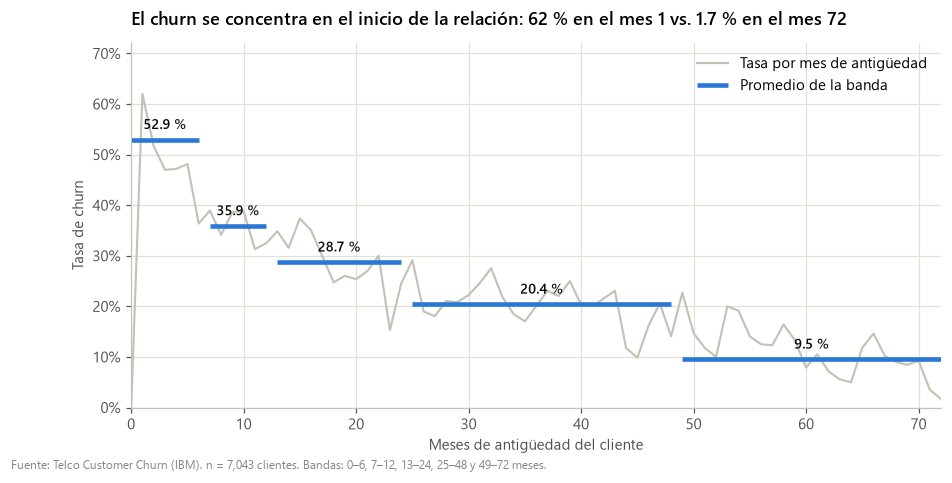

In [27]:
por_mes = df_analitico.groupby("antiguedad_meses").agg(clientes=("customer_id", "nunique"), tasa_churn=("churn", "mean"))

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(por_mes.index, por_mes["tasa_churn"], color=GRIS_CLARO, lw=1.4, label="Tasa por mes de antigüedad")
for desde, hasta, etiqueta in BANDAS:
    t = agg_tiempo.loc[etiqueta, "tasa_churn"]
    ax.hlines(t, desde, hasta, color=AZUL, lw=3, label="Promedio de la banda" if desde == 0 else None)
    ax.annotate(pct(t), ((desde + hasta) / 2, t), xytext=(0, 7), textcoords="offset points", ha="center", color=TINTA, fontsize=9, fontweight="semibold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 72)
ax.set_ylim(0, 0.72)
ax.set_xlabel("Meses de antigüedad del cliente")
ax.set_ylabel("Tasa de churn")
ax.set_title(f"El churn se concentra en el inicio de la relación: {pct(por_mes.loc[1, 'tasa_churn'], 0)} en el mes 1 vs. {pct(por_mes.loc[72, 'tasa_churn'])} en el mes 72")
ax.legend(loc="upper right")
fig.text(0.01, -0.02, f"Fuente: Telco Customer Churn (IBM). n = {KPI['clientes']:,} clientes. Bandas: 0–6, 7–12, 13–24, 25–48 y 49–72 meses.", color=GRIS, fontsize=8)
guardar(fig, "f01_churn_ciclo_vida")

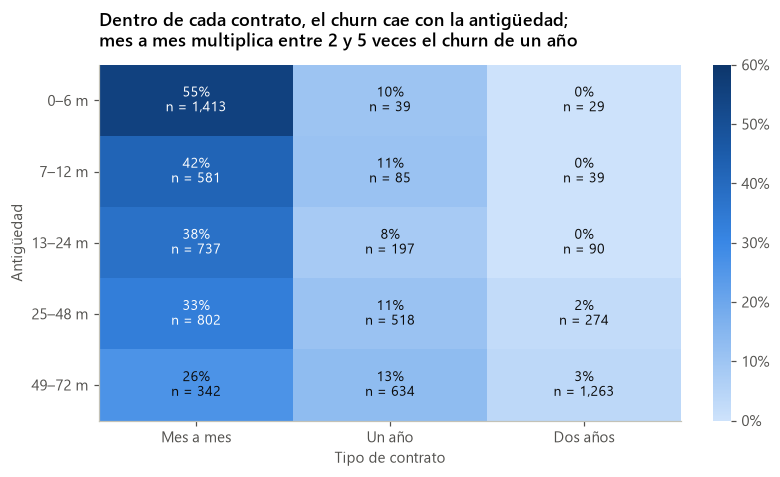

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(tabla_cruzada.values, cmap=RAMPA_AZUL, vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(ORDEN_CONTRATO)), ORDEN_CONTRATO)
ax.set_yticks(range(len(ORDEN_BANDAS)), ORDEN_BANDAS)
ax.grid(False)
for i in range(tabla_cruzada.shape[0]):
    for j in range(tabla_cruzada.shape[1]):
        valor, n = tabla_cruzada.iat[i, j], tabla_cruzada_n.iat[i, j]
        ax.text(j, i, f"{valor:.0%}\nn = {n:,}", ha="center", va="center", fontsize=9, color="white" if valor > 0.3 else TINTA)
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Antigüedad")
ax.set_title("Dentro de cada contrato, el churn cae con la antigüedad;\nmes a mes multiplica entre 2 y 5 veces el churn de un año")
cbar = fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0, decimals=0), fraction=0.04)
cbar.outline.set_visible(False)
guardar(fig, "f02_heatmap_contrato_antiguedad")

**Qué muestra.** El churn baja de 52.9 % (0–6 meses) a 9.5 % (49–72 meses), con el pico en el primer mes (62 %).
**Qué significa.** Los primeros meses son la ventana crítica: la mayoría de la pérdida ocurre antes de que el cliente consolide la relación. El patrón se mantiene dentro de cada contrato, así que no es solo un efecto de mezcla.
**Qué implica.** Una intervención de onboarding temprano (meses 1 a 3) ataca la etapa de mayor riesgo. *Limitación:* los clientes antiguos son, por construcción, sobrevivientes (sesgo de supervivencia). La curva describe tasas condicionales por antigüedad y no la trayectoria de una cohorte de altas.

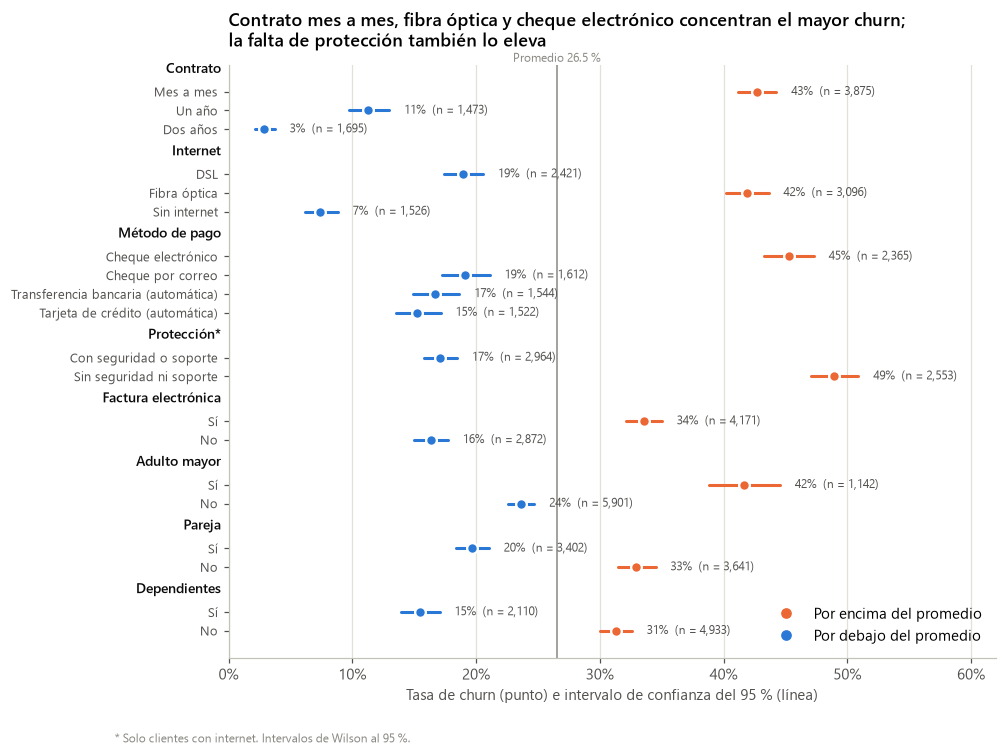

In [29]:
def ic_wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson para una proporción (más estable que el de Wald con tasas extremas)
    p = k / n
    den = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / den
    margen = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return centro - margen, centro + margen


factores = [
    ("Contrato", "contrato", ORDEN_CONTRATO, None),
    ("Internet", "servicio_internet", ORDEN_INTERNET, None),
    ("Método de pago", "metodo_pago", ORDEN_PAGO, None),
    ("Protección*", "tiene_proteccion", [1, 0], df_analitico["tiene_internet"] == 1),
    ("Factura electrónica", "facturacion_electronica", ["Sí", "No"], None),
    ("Adulto mayor", "adulto_mayor", ["Sí", "No"], None),
    ("Pareja", "pareja", ["Sí", "No"], None),
    ("Dependientes", "dependientes", ["Sí", "No"], None),
]
filas = []
for grupo, col, orden, filtro in factores:
    base = df_analitico if filtro is None else df_analitico[filtro]
    for valor in orden:
        sub = base[base[col] == valor]
        lo, hi = ic_wilson(sub["churn"].sum(), len(sub))
        etiqueta = {1: "Con seguridad o soporte", 0: "Sin seguridad ni soporte"}.get(valor, valor) if col == "tiene_proteccion" else valor
        filas.append({"factor": grupo, "categoria": etiqueta, "clientes": len(sub), "tasa_churn": sub["churn"].mean(), "ic_inf": lo, "ic_sup": hi,
                      "mrr_perdido": sub["mrr_perdido"].sum()})
segmentacion = pd.DataFrame(filas)
segmentacion.to_csv(DIR_TAB / "segmentacion_churn.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(9, 7))
y, ticks, etiquetas = 0, [], []
for grupo, sub in segmentacion.groupby("factor", sort=False):
    ax.text(-0.01, y + 0.15, grupo, transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontweight="semibold", color=TINTA, fontsize=9)
    y += 1
    for _, fila in sub.iterrows():
        alto = fila["tasa_churn"] > KPI["tasa_churn"]
        ax.plot([fila["ic_inf"], fila["ic_sup"]], [y, y], color=NARANJA if alto else AZUL, lw=2, solid_capstyle="round")
        ax.plot(fila["tasa_churn"], y, "o", ms=7, color=NARANJA if alto else AZUL, mec="white", mew=1.5)
        ax.text(fila["ic_sup"] + 0.012, y, f"{fila['tasa_churn']:.0%}  (n = {fila['clientes']:,})", va="center", fontsize=8, color=TINTA_2)
        ticks.append(y)
        etiquetas.append(fila["categoria"])
        y += 1
    y += 0.4
ax.axvline(KPI["tasa_churn"], color=GRIS, lw=1)
ax.text(KPI["tasa_churn"], -0.6, f"Promedio {pct(KPI['tasa_churn'])}", ha="center", color=GRIS, fontsize=8)
ax.set_yticks(ticks, etiquetas, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, 0.62)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Tasa de churn (punto) e intervalo de confianza del 95 % (línea)")
ax.grid(axis="y", visible=False)
ax.plot([], [], "o", color=NARANJA, label="Por encima del promedio")
ax.plot([], [], "o", color=AZUL, label="Por debajo del promedio")
ax.legend(loc="lower right")
ax.set_title("Contrato mes a mes, fibra óptica y cheque electrónico concentran el mayor churn;\nla falta de protección también lo eleva")
fig.text(0.01, 0.0, "* Solo clientes con internet. Intervalos de Wilson al 95 %.", color=GRIS, fontsize=8)
guardar(fig, "f03_churn_por_segmento")

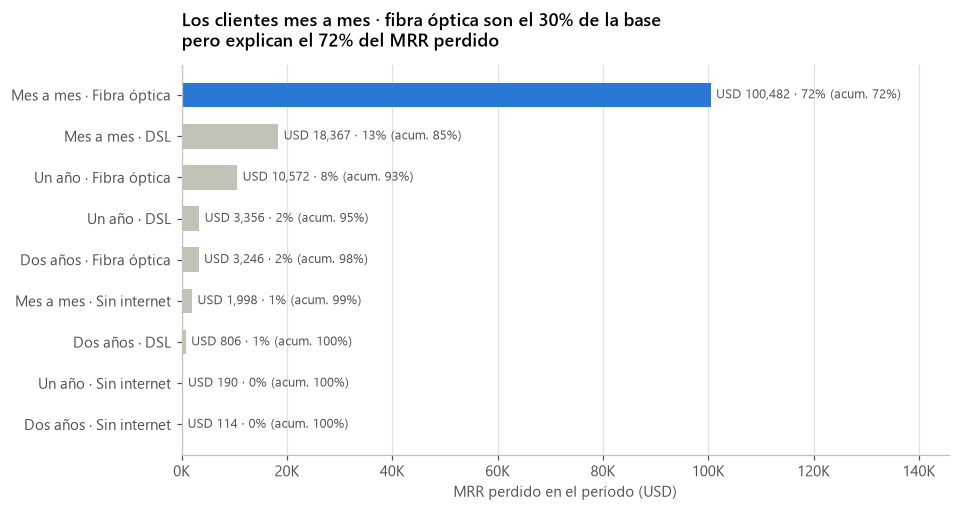

In [30]:
# 9.3 Contribución al MRR perdido por segmento (contrato × internet): ¿dónde se concentra la pérdida?
contrib = resumen(df_analitico, ["contrato", "servicio_internet"]).reset_index()
contrib["segmento"] = contrib["contrato"] + " · " + contrib["servicio_internet"]
contrib["participacion_clientes"] = contrib["clientes"] / contrib["clientes"].sum()
contrib = contrib.sort_values("mrr_perdido", ascending=False).reset_index(drop=True)
contrib["participacion_acumulada"] = contrib["participacion_mrr_perdido"].cumsum()
contrib.to_csv(DIR_TAB / "contribucion_mrr_perdido.csv", index=False, encoding="utf-8-sig")
lider = contrib.iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.6))
colores = [AZUL if i == 0 else GRIS_CLARO for i in range(len(contrib))]
ax.barh(contrib["segmento"], contrib["mrr_perdido"], color=colores, height=0.6)
for i, fila in contrib.iterrows():
    ax.text(fila["mrr_perdido"] + 1000, i, f"{usd(fila['mrr_perdido'])} · {fila['participacion_mrr_perdido']:.0%} (acum. {fila['participacion_acumulada']:.0%})",
            va="center", fontsize=8.5, color=TINTA_2)
ax.invert_yaxis()
ax.set_xlim(0, contrib["mrr_perdido"].max() * 1.45)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K"))
ax.set_xlabel("MRR perdido en el período (USD)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Los clientes {lider['segmento'].lower()} son el {lider['participacion_clientes']:.0%} de la base\npero explican el {lider['participacion_mrr_perdido']:.0%} del MRR perdido")
guardar(fig, "f04_contribucion_mrr_perdido")

In [31]:
# 9.4 Drivers ajustados: regresión logística implementada con numpy (IRLS) para que cada coeficiente sea auditable
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def ajustar_logit(X, y, max_iter=50, tol=1e-9):
    # Newton-Raphson / IRLS: devuelve coeficientes y errores estándar
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        p = sigmoide(X @ beta)
        hess = X.T @ (X * (p * (1 - p))[:, None])
        paso = np.linalg.solve(hess, X.T @ (y - p))
        beta += paso
        if np.abs(paso).max() < tol:
            break
    return beta, np.sqrt(np.diag(np.linalg.inv(hess)))


def matriz_diseno(d):
    # Categorías de referencia: mes a mes, 49–72 meses, DSL, pago distinto de cheque electrónico
    si = lambda col: d[col].eq("Sí")
    return pd.DataFrame({
        "Intercepto": 1.0,
        "Contrato un año": d["contrato"].eq("Un año"),
        "Contrato dos años": d["contrato"].eq("Dos años"),
        "Antigüedad 0–6 m": d["banda_antiguedad"].eq("0–6 m"),
        "Antigüedad 7–12 m": d["banda_antiguedad"].eq("7–12 m"),
        "Antigüedad 13–24 m": d["banda_antiguedad"].eq("13–24 m"),
        "Antigüedad 25–48 m": d["banda_antiguedad"].eq("25–48 m"),
        "Fibra óptica": d["servicio_internet"].eq("Fibra óptica"),
        "Sin internet": d["servicio_internet"].eq("Sin internet"),
        "Cheque electrónico": d["metodo_pago"].eq("Cheque electrónico"),
        "Factura electrónica": si("facturacion_electronica"),
        "Adulto mayor": si("adulto_mayor"),
        "Pareja": si("pareja"),
        "Dependientes": si("dependientes"),
        "Seguridad online": si("seguridad_online"),
        "Soporte técnico": si("soporte_tecnico"),
        "Backup online": si("backup_online"),
        "Protección de equipo": si("proteccion_equipo"),
        "Streaming TV": si("streaming_tv"),
        "Streaming películas": si("streaming_peliculas"),
        "Líneas múltiples": si("lineas_multiples"),
    }).astype(float)


X = matriz_diseno(df_analitico)
y = df_analitico["churn"].to_numpy(dtype=float)
beta, se = ajustar_logit(X.to_numpy(), y)
z = beta / se
p_valor = np.array([2 * (1 - 0.5 * (1 + erf(abs(v) / sqrt(2)))) for v in z])
drivers = pd.DataFrame({
    "factor": X.columns, "coeficiente": beta, "odds_ratio": np.exp(beta),
    "ic_inf": np.exp(beta - 1.96 * se), "ic_sup": np.exp(beta + 1.96 * se), "p_valor": p_valor,
}).query("factor != 'Intercepto'")
drivers["direccion"] = np.where(drivers["p_valor"] >= 0.05, "No significativo", np.where(drivers["odds_ratio"] > 1, "Aumenta el riesgo", "Reduce el riesgo"))
drivers = drivers.sort_values("odds_ratio", ascending=False).reset_index(drop=True)
drivers.to_csv(DIR_TAB / "drivers_modelo_logistico.csv", index=False, encoding="utf-8-sig")
drivers.style.format({"coeficiente": "{:.3f}", "odds_ratio": "{:.2f}", "ic_inf": "{:.2f}", "ic_sup": "{:.2f}", "p_valor": "{:.4f}"})

,factor,coeficiente,odds_ratio,ic_inf,ic_sup,p_valor,direccion
0,Antigüedad 0–6 m,1.931,6.90,5.25,9.07,0.0000,Aumenta el riesgo
1,Antigüedad 7–12 m,1.075,2.93,2.21,3.89,0.0000,Aumenta el riesgo
2,Fibra óptica,0.758,2.13,1.81,2.51,0.0000,Aumenta el riesgo
3,Antigüedad 13–24 m,0.737,2.09,1.62,2.70,0.0000,Aumenta el riesgo
4,Antigüedad 25–48 m,0.367,1.44,1.15,1.81,0.0015,Aumenta el riesgo
5,Cheque electrónico,0.351,1.42,1.24,1.63,0.0000,Aumenta el riesgo
6,Factura electrónica,0.351,1.42,1.23,1.65,0.0000,Aumenta el riesgo
7,Streaming películas,0.313,1.37,1.17,1.60,0.0001,Aumenta el riesgo
8,Streaming TV,0.292,1.34,1.14,1.57,0.0003,Aumenta el riesgo
9,Líneas múltiples,0.253,1.29,1.11,1.50,0.0011,Aumenta el riesgo


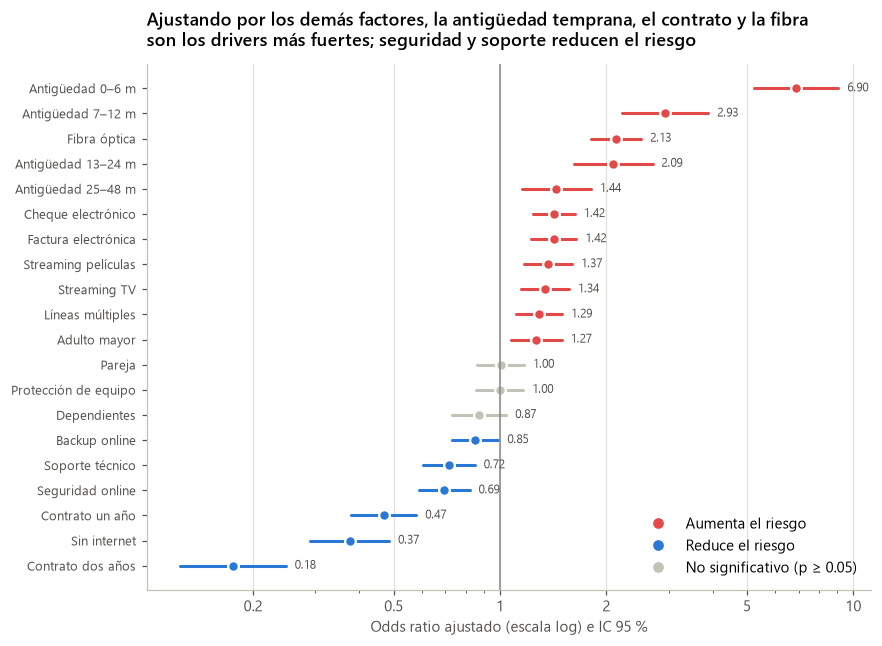

In [32]:
ROJO_DIV = "#e34948"
fig, ax = plt.subplots(figsize=(8.5, 6.2))
for i, fila in drivers.iterrows():
    color = GRIS_CLARO if fila["direccion"] == "No significativo" else (ROJO_DIV if fila["odds_ratio"] > 1 else AZUL)
    ax.plot([fila["ic_inf"], fila["ic_sup"]], [i, i], color=color, lw=2, solid_capstyle="round")
    ax.plot(fila["odds_ratio"], i, "o", ms=7, color=color, mec="white", mew=1.5)
    ax.text(fila["ic_sup"] * 1.06, i, f"{fila['odds_ratio']:.2f}", va="center", fontsize=8, color=TINTA_2)
ax.axvline(1, color=GRIS, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10], ["0.2", "0.5", "1", "2", "5", "10"])
ax.set_yticks(range(len(drivers)), drivers["factor"], fontsize=8.5)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio ajustado (escala log) e IC 95 %")
for color, texto in [(ROJO_DIV, "Aumenta el riesgo"), (AZUL, "Reduce el riesgo"), (GRIS_CLARO, "No significativo (p ≥ 0.05)")]:
    ax.plot([], [], "o", color=color, label=texto)
ax.legend(loc="lower right")
ax.set_title("Ajustando por los demás factores, la antigüedad temprana, el contrato y la fibra\nson los drivers más fuertes; seguridad y soporte reducen el riesgo")
guardar(fig, "f05_drivers_odds_ratio")

**Lectura de los drivers (asociación ajustada, no causalidad).**

- **Antigüedad temprana (OR ≈ 6.9 para 0–6 meses frente a 49–72) y contrato** (dos años OR ≈ 0.18 y un año OR ≈ 0.47 frente a mes a mes): son los factores dominantes incluso controlando por servicio y pago.
- **Fibra óptica (OR ≈ 2.1)**: el riesgo alto persiste aun ajustando por contrato y servicios. Es una señal de un problema de propuesta de valor (precio o calidad) que estos datos no permiten diagnosticar; corresponde a la alternativa D.
- **Cheque electrónico (OR ≈ 1.4) y factura electrónica (OR ≈ 1.4)**: la fricción de pago es una palanca operativa de bajo costo.
- **Seguridad online (OR ≈ 0.70) y soporte técnico (OR ≈ 0.72)** reducen el riesgo. En cambio, streaming y líneas múltiples lo aumentan (OR ≈ 1.3), probablemente porque elevan la factura y la sensibilidad al precio.
- **Pareja y dependientes** dejan de ser significativos al ajustar, porque su efecto bruto se explicaba por contrato y antigüedad.

In [33]:
# 9.5 Uplift descriptivo: comparaciones dentro de estratos homogéneos (diferencia en puntos porcentuales e IC 95 %)
def comparar(d, mascara_a, mascara_b, estrato, factor, etiqueta_a, etiqueta_b):
    a_, b_ = d.loc[mascara_a, "churn"], d.loc[mascara_b, "churn"]
    pa, pb = a_.mean(), b_.mean()
    se_dif = np.sqrt(pa * (1 - pa) / len(a_) + pb * (1 - pb) / len(b_))
    return {"estrato": estrato, "comparación": f"{etiqueta_a} vs. {etiqueta_b}", "factor": factor,
            "n_a": len(a_), "churn_a": pa, "n_b": len(b_), "churn_b": pb,
            "diferencia_pp": (pa - pb) * 100, "ic_inf_pp": (pa - pb - 1.96 * se_dif) * 100, "ic_sup_pp": (pa - pb + 1.96 * se_dif) * 100,
            "uplift_relativo": (pa - pb) / pb}


d = df_analitico
mm_fibra = (d.contrato == "Mes a mes") & (d.servicio_internet == "Fibra óptica")
nuevos_internet = (d.antiguedad_meses <= 12) & (d.tiene_internet == 1)
uplift = pd.DataFrame([
    comparar(d, mm_fibra & (d.seguridad_online == "Sí"), mm_fibra & (d.seguridad_online == "No"), "Mes a mes + fibra", "Seguridad online", "Con", "Sin"),
    comparar(d, mm_fibra & (d.soporte_tecnico == "Sí"), mm_fibra & (d.soporte_tecnico == "No"), "Mes a mes + fibra", "Soporte técnico", "Con", "Sin"),
    comparar(d, mm_fibra & (d.pago_automatico == 1), mm_fibra & (d.metodo_pago == "Cheque electrónico"), "Mes a mes + fibra", "Método de pago", "Automático", "Cheque electrónico"),
    comparar(d, nuevos_internet & (d.tiene_proteccion == 1), nuevos_internet & (d.tiene_proteccion == 0), "Nuevos (0–12 m) con internet", "Protección", "Con", "Sin"),
    comparar(d, (d.antiguedad_meses <= 12) & (d.contrato == "Un año"), (d.antiguedad_meses <= 12) & (d.contrato == "Mes a mes"), "Nuevos (0–12 m)", "Contrato", "Un año", "Mes a mes"),
])
uplift.to_csv(DIR_TAB / "uplift_descriptivo.csv", index=False, encoding="utf-8-sig")
uplift.style.format({"churn_a": "{:.1%}", "churn_b": "{:.1%}", "diferencia_pp": "{:+.1f}", "ic_inf_pp": "{:+.1f}", "ic_sup_pp": "{:+.1f}", "uplift_relativo": "{:+.0%}"})

,estrato,comparación,factor,n_a,churn_a,n_b,churn_b,diferencia_pp,ic_inf_pp,ic_sup_pp,uplift_relativo
0,Mes a mes + fibra,Con vs. Sin,Seguridad online,354,37.0%,1774,58.1%,-21.1,-26.6,-15.6,-36%
1,Mes a mes + fibra,Con vs. Sin,Soporte técnico,332,38.9%,1796,57.5%,-18.7,-24.4,-12.9,-32%
2,Mes a mes + fibra,Automático vs. Cheque electrónico,Método de pago,620,43.7%,1307,60.4%,-16.7,-21.4,-11.9,-28%
3,Nuevos (0–12 m) con internet,Con vs. Sin,Protección,470,37.0%,1203,64.1%,-27.1,-32.2,-21.9,-42%
4,Nuevos (0–12 m),Un año vs. Mes a mes,Contrato,124,10.5%,1994,51.4%,-40.9,-46.7,-35.0,-80%


Dentro del estrato de mayor riesgo (mes a mes con fibra), tener seguridad online o soporte técnico se asocia con **unos 20 puntos porcentuales menos de churn**, y el pago automático con unos 17 pp menos que el cheque electrónico. Estas diferencias son **asociaciones observacionales**: quienes contratan protección o pago automático pueden ser clientes más comprometidos (sesgo de selección). Por eso no se usan como efecto causal. Sirven para **acotar** los supuestos de reducción atribuible de cada palanca (sección 10), que se descuentan fuertemente, y para justificar un **experimento con grupo control** antes de escalar.

### 9.6 Resumen de hallazgos

| # | Qué muestra | Qué significa | Qué implica |
|---|---|---|---|
| H1 | 30.5 % del MRR se pierde por churn en el período; quienes abandonan pagan más (USD 74 vs. USD 61) | El problema es de valor, no solo de volumen | Usar % MRR retenido como North Star, no el conteo de clientes |
| H2 | Mes a mes con fibra: ≈ 30 % de los clientes y ≈ 72 % del MRR perdido | La pérdida está muy concentrada | Focalizar en ese segmento; un descuento masivo desperdicia presupuesto |
| H3 | El churn de 0–6 meses es 52.9 % y baja con la antigüedad dentro de cada contrato | Los primeros meses son la ventana crítica | Onboarding temprano (L4) |
| H4 | Seguridad y soporte reducen el riesgo (OR ≈ 0.7); hay ≈ 20 pp de diferencia en mes a mes + fibra | La protección aumenta el valor percibido | Bundle de protección para fibra (L2) |
| H5 | Cheque electrónico +42 % de odds; −17 pp con pago automático en el estrato crítico | La fricción de pago acompaña al abandono | Incentivo de pago automático (L3) |
| H6 | La fibra mantiene OR ≈ 2.1 ajustado | Hay un problema estructural de propuesta de valor | Alternativa D: investigar precio y calidad (requiere más datos) |

## 10. Priorización y medición de impacto

La decisión no es solo *a quién* intervenir, sino *con qué palanca* y *si vale la pena*. Esta sección construye un **score de riesgo** para ordenar a los clientes activos, una **matriz de priorización de segmentos**, la asignación de **palancas**, la **simulación de ROI** con escenarios y sensibilidad (Sesión 5) y el **diseño del piloto A/B** que validará el efecto (Sesión 6).

### 10.1 Score de riesgo de churn (validación fuera de muestra)

Se usa el mismo modelo logístico de 9.4, pero cada cliente recibe una probabilidad estimada por un modelo que **no lo vio al entrenar** (validación cruzada de 5 pliegues). Esa probabilidad es la de abandonar en un período como el del corte. **Sirve para ordenar y priorizar, no como pronóstico exacto.**

In [34]:
def auc(prob, real):
    # AUC por rangos (equivale a la probabilidad de que un churner tenga mayor score que un activo)
    rangos = pd.Series(prob).rank().to_numpy()
    n1 = real.sum()
    n0 = len(real) - n1
    return (rangos[real == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


rng = np.random.default_rng(SEMILLA)
pliegue = rng.permutation(len(df_analitico)) % 5
Xv = X.to_numpy()
prob_oof = np.zeros(len(df_analitico))
for k in range(5):
    entrena = pliegue != k
    beta_k, _ = ajustar_logit(Xv[entrena], y[entrena])
    prob_oof[~entrena] = sigmoide(Xv[~entrena] @ beta_k)

df_analitico["prob_churn"] = prob_oof
AUC_OOF = auc(prob_oof, y)
calibracion = (df_analitico.assign(decil=pd.qcut(prob_oof, 10, labels=False) + 1)
               .groupby("decil").agg(clientes=("churn", "size"), prob_media=("prob_churn", "mean"), tasa_observada=("churn", "mean")))
print(f"AUC fuera de muestra (5 pliegues): {AUC_OOF:.3f}")
calibracion.style.format({"prob_media": "{:.1%}", "tasa_observada": "{:.1%}"})

AUC fuera de muestra (5 pliegues): 0.846


,clientes,prob_media,tasa_observada
decil,,,
1,705,0.9%,1.3%
2,704,2.2%,1.3%
3,704,4.5%,5.3%
4,709,8.5%,9.4%
5,718,15.2%,15.3%
6,686,22.9%,22.3%
7,704,32.7%,33.9%
8,706,44.9%,42.8%
9,703,58.0%,59.9%


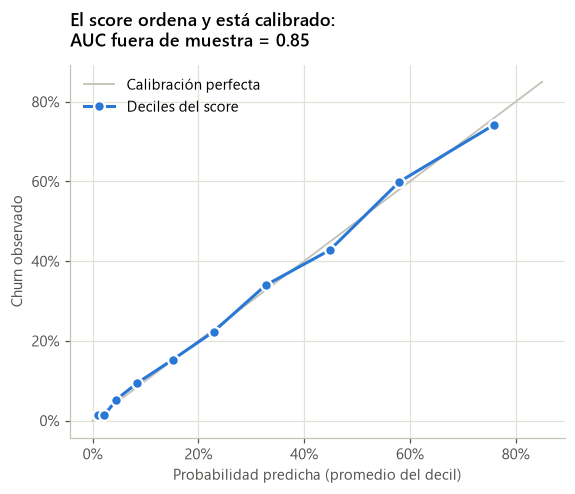

In [35]:
fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.plot([0, 0.85], [0, 0.85], color=GRIS_CLARO, lw=1.2, label="Calibración perfecta")
ax.plot(calibracion["prob_media"], calibracion["tasa_observada"], "-o", color=AZUL, lw=2, ms=7, mec="white", mew=1.5, label="Deciles del score")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Probabilidad predicha (promedio del decil)")
ax.set_ylabel("Churn observado")
ax.legend(loc="upper left")
ax.set_title(f"El score ordena y está calibrado:\nAUC fuera de muestra = {AUC_OOF:.2f}")
guardar(fig, "f06_calibracion_score")

In [36]:
UMBRAL_ALTO, UMBRAL_MEDIO = 0.40, 0.20
activos_mask = df_analitico["churn"] == 0
df_analitico["riesgo"] = np.select(
    [~activos_mask, df_analitico["prob_churn"] >= UMBRAL_ALTO, df_analitico["prob_churn"] >= UMBRAL_MEDIO],
    ["No aplica (abandonó)", "Alto", "Medio"], default="Bajo")
df_analitico["mrr_riesgo_esperado"] = np.where(activos_mask, df_analitico["prob_churn"] * df_analitico["cargo_mensual"], 0.0)

activos = df_analitico[activos_mask]
niveles_riesgo = (activos.groupby("riesgo").agg(clientes=("customer_id", "nunique"), mrr=("cargo_mensual", "sum"),
                                                mrr_riesgo_esperado=("mrr_riesgo_esperado", "sum"), prob_media=("prob_churn", "mean"))
                  .loc[["Alto", "Medio", "Bajo"]])
niveles_riesgo["participacion_clientes"] = niveles_riesgo["clientes"] / niveles_riesgo["clientes"].sum()
niveles_riesgo["participacion_riesgo"] = niveles_riesgo["mrr_riesgo_esperado"] / niveles_riesgo["mrr_riesgo_esperado"].sum()
niveles_riesgo.to_csv(DIR_TAB / "niveles_riesgo.csv", encoding="utf-8-sig")
niveles_riesgo

,clientes,mrr,mrr_riesgo_esperado,prob_media,participacion_clientes,participacion_riesgo
riesgo,,,,,,
Alto,820,"64,084.7000","35,999.5336",0.5587,0.1585,0.5287
Medio,972,"65,089.4000","18,887.8788",0.2855,0.1879,0.2774
Bajo,3382,"187,811.6500","13,209.0564",0.0628,0.6537,0.1940


Los clientes activos de **riesgo alto** (score ≥ 40 %) son pocos, pero concentran más de la mitad del MRR en riesgo esperado. Esa es la lista de trabajo semanal de la Gerencia de Retención.

### 10.2 Matriz de priorización de segmentos

Segmento = contrato × internet × etapa de ciclo de vida. Para cada uno se calcula el riesgo (tasa de churn del corte) y el valor en juego (MRR en riesgo esperado de sus clientes activos). **Regla de prioridad:**

- **P1, intervenir ahora**: churn ≥ 40 % y ≥ 5 % del MRR en riesgo total.
- **P2, intervenir focalizado**: churn ≥ 40 % o ≥ 5 % del MRR en riesgo.
- **P3, monitorear**: el resto, y todo segmento con menos de 30 clientes (muestra insuficiente para clasificarlo).

In [37]:
def asignar_palanca(d):
    # Una palanca principal por cliente activo, en orden de costo y retorno esperado (ver 10.3)
    condiciones = [
        d["antiguedad_meses"] <= 6,
        (d["servicio_internet"] == "Fibra óptica") & (d["tiene_proteccion"] == 0),
        d["metodo_pago"] == "Cheque electrónico",
        d["contrato"] == "Mes a mes",
    ]
    palanca = np.select(condiciones, ["L4", "L2", "L3", "L1"], default="L0")
    return np.where(d["churn"] == 0, palanca, "NA")


df_analitico["palanca_id"] = asignar_palanca(df_analitico)
df_analitico["segmento"] = df_analitico["contrato"] + " · " + df_analitico["servicio_internet"] + " · " + df_analitico["etapa_ciclo_vida"].astype(str)

seg = df_analitico.groupby(["contrato", "servicio_internet", "etapa_ciclo_vida", "segmento"], observed=True).agg(
    clientes=("customer_id", "nunique"), churners=("churn", "sum"), mrr_perdido=("mrr_perdido", "sum")).reset_index()
seg_activos = activos.assign(palanca_id=df_analitico.loc[activos_mask, "palanca_id"],
                             segmento=df_analitico.loc[activos_mask, "segmento"]).groupby("segmento").agg(
    clientes_activos=("customer_id", "nunique"), mrr_activo=("cargo_mensual", "sum"), mrr_riesgo_esperado=("mrr_riesgo_esperado", "sum"),
    activos_riesgo_alto=("riesgo", lambda s: int((s == "Alto").sum())),
    palanca_dominante=("palanca_id", lambda s: s[s != "L0"].mode().iat[0] if (s != "L0").any() else "L0"))
seg = seg.merge(seg_activos, on="segmento", how="left").fillna({"clientes_activos": 0, "mrr_activo": 0, "mrr_riesgo_esperado": 0, "activos_riesgo_alto": 0, "palanca_dominante": "L0"})
seg["tasa_churn"] = seg["churners"] / seg["clientes"]
seg["participacion_riesgo"] = seg["mrr_riesgo_esperado"] / seg["mrr_riesgo_esperado"].sum()
muestra_suficiente = seg["clientes"] >= 30
seg["prioridad"] = np.select(
    [muestra_suficiente & (seg["tasa_churn"] >= 0.40) & (seg["participacion_riesgo"] >= 0.05),
     muestra_suficiente & ((seg["tasa_churn"] >= 0.40) | (seg["participacion_riesgo"] >= 0.05))],
    ["P1 · Intervenir ahora", "P2 · Intervenir focalizado"], default="P3 · Monitorear")
seg = seg.sort_values(["prioridad", "mrr_riesgo_esperado"], ascending=[True, False]).reset_index(drop=True)
seg.insert(0, "segmento_id", [f"S{i + 1:02d}" for i in range(len(seg))])
seg[["segmento_id", "segmento", "clientes", "tasa_churn", "clientes_activos", "mrr_riesgo_esperado", "participacion_riesgo", "prioridad", "palanca_dominante"]].head(12).style.format(
    {"tasa_churn": "{:.1%}", "mrr_riesgo_esperado": "{:,.0f}", "participacion_riesgo": "{:.1%}"})

,segmento_id,segmento,clientes,tasa_churn,clientes_activos,mrr_riesgo_esperado,participacion_riesgo,prioridad,palanca_dominante
0,S01,Mes a mes · Fibra óptica · En desarrollo (13–48 m),946,46.6%,505,"19,592",28.8%,P1 · Intervenir ahora,L2
1,S02,Mes a mes · Fibra óptica · Nuevo (0–12 m),916,70.2%,273,"14,568",21.4%,P1 · Intervenir ahora,L4
2,S03,Mes a mes · DSL · Nuevo (0–12 m),690,42.5%,397,"7,861",11.5%,P1 · Intervenir ahora,L4
3,S04,Mes a mes · Fibra óptica · Consolidado (49–72 m),266,29.3%,188,"5,699",8.4%,P2 · Intervenir focalizado,L2
4,S05,Un año · Fibra óptica · Consolidado (49–72 m),355,18.9%,288,"4,953",7.3%,P2 · Intervenir focalizado,L2
5,S06,Mes a mes · DSL · En desarrollo (13–48 m),459,19.8%,368,"3,862",5.7%,P2 · Intervenir focalizado,L1
6,S07,Un año · Fibra óptica · En desarrollo (13–48 m),177,19.8%,142,"2,931",4.3%,P3 · Monitorear,L2
7,S08,Dos años · Fibra óptica · Consolidado (49–72 m),393,7.1%,365,"2,280",3.3%,P3 · Monitorear,L3
8,S09,Un año · DSL · En desarrollo (13–48 m),320,10.3%,287,"1,518",2.2%,P3 · Monitorear,L3
9,S10,Mes a mes · Sin internet · Nuevo (0–12 m),388,22.7%,300,"1,235",1.8%,P3 · Monitorear,L4


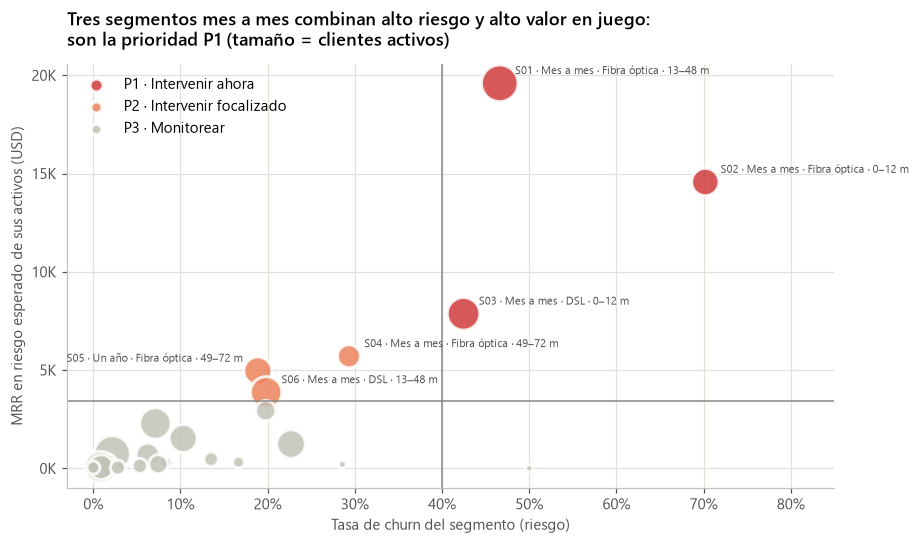

In [38]:
colores_prioridad = {"P1 · Intervenir ahora": CRITICO, "P2 · Intervenir focalizado": SERIO, "P3 · Monitorear": GRIS_CLARO}
fig, ax = plt.subplots(figsize=(9, 5))
for prioridad, sub in seg.groupby("prioridad"):
    ax.scatter(sub["tasa_churn"], sub["mrr_riesgo_esperado"], s=sub["clientes_activos"] * 1.1 + 20, color=colores_prioridad[prioridad],
               alpha=0.85, edgecolor="white", linewidth=2, label=prioridad)
ETAPA_CORTA = {"Nuevo (0–12 m)": "0–12 m", "En desarrollo (13–48 m)": "13–48 m", "Consolidado (49–72 m)": "49–72 m"}
etiquetados = seg[seg["prioridad"] != "P3 · Monitorear"].reset_index(drop=True)
for i, fila in etiquetados.iterrows():
    texto = f"{fila['segmento_id']} · {fila['contrato']} · {fila['servicio_internet']} · {ETAPA_CORTA[str(fila['etapa_ciclo_vida'])]}"
    a_la_izquierda = fila["prioridad"].startswith("P2") and i % 2 == 0
    ax.annotate(texto, (fila["tasa_churn"], fila["mrr_riesgo_esperado"]), xytext=(-10 if a_la_izquierda else 10, 6),
                textcoords="offset points", ha="right" if a_la_izquierda else "left", fontsize=7.5, color=TINTA_2)
ax.axvline(0.40, color=GRIS, lw=1)
ax.axhline(seg["mrr_riesgo_esperado"].sum() * 0.05, color=GRIS, lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(5000))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K"))
ax.set_xlim(-0.03, 0.85)
ax.set_xlabel("Tasa de churn del segmento (riesgo)")
ax.set_ylabel("MRR en riesgo esperado de sus activos (USD)")
ax.legend(loc="upper left", markerscale=0.4)
ax.set_title("Tres segmentos mes a mes combinan alto riesgo y alto valor en juego:\nson la prioridad P1 (tamaño = clientes activos)")
guardar(fig, "f07_matriz_priorizacion")
seg.to_csv(DIR_TAB / "priorizacion_segmentos.csv", index=False, encoding="utf-8-sig")

### 10.3 Palancas de retención y supuestos explícitos

Cada cliente activo recibe **una palanca principal**, asignada en este orden: L4, L2, L3 y L1. Las palancas de menor costo van primero y la de descuento queda al final porque presiona el ARPU.

| ID | Palanca | Elegibles | Incentivo (costo) | Evidencia que acota el efecto | Responsable |
|---|---|---|---|---|---|
| L4 | Onboarding temprano | Antigüedad ≤ 6 meses | Sesión de acompañamiento en los meses 1 a 3: USD 8 por cliente contactado | H3: churn 52.9 % en 0–6 m (no hay evidencia directa de efecto) | Customer Success |
| L2 | Bundle de protección | Fibra sin seguridad ni soporte | 3 meses sin costo de seguridad + soporte (precio de lista USD 10.05/mes; costo = costo variable de prestarlo) | H4: ≈ 20 pp menos de churn en mes a mes + fibra (observacional) | Producto / Marketing |
| L3 | Pago automático | Cheque electrónico | Crédito único de USD 10 | H5: OR 1.42; ≈ 17 pp de diferencia en el estrato crítico | Facturación |
| L1 | Migración a contrato anual | Mes a mes | 10 % de descuento por 12 meses (1.2 × cargo mensual) | Brecha mes a mes vs. un año (≈ 41 pp en nuevos), muy afectada por autoselección | Comercial de retención |
| L0 | Sin palanca prioritaria | Resto de activos | — | — | Monitoreo |

**Supuestos por escenario** (Sesión 5: el escenario conservador es el peor caso defendible y el optimista solo es válido si hay evidencia). La *reducción atribuible* es la fracción del riesgo de churn que se elimina entre quienes aceptan. Se fija muy por debajo de las brechas observadas para descontar la autoselección.

In [39]:
ESCENARIOS = {"Conservador": {"margen": 0.45, "horizonte_meses": 6},
              "Base": {"margen": 0.55, "horizonte_meses": 12},
              "Optimista": {"margen": 0.65, "horizonte_meses": 18}}
EFECTO_PALANCA = {  # (conservador, base, optimista)
    "L1": {"aceptacion": (0.15, 0.25, 0.35), "reduccion": (0.20, 0.35, 0.50)},
    "L2": {"aceptacion": (0.20, 0.30, 0.40), "reduccion": (0.10, 0.20, 0.30)},
    "L3": {"aceptacion": (0.20, 0.30, 0.40), "reduccion": (0.10, 0.15, 0.25)},
    "L4": {"aceptacion": (0.50, 0.65, 0.80), "reduccion": (0.05, 0.10, 0.20)},
}
PRECIO_BUNDLE = LISTA_PRECIOS["Seguridad online"] + LISTA_PRECIOS["Soporte técnico"]
PALANCAS = pd.DataFrame([
    ["L4", "Onboarding temprano", "Acompañamiento proactivo en los meses 1 a 3 de la relación", "Customer Success", "Bajo", 1],
    ["L2", "Bundle de protección", "3 meses sin costo de seguridad online + soporte técnico", "Producto / Marketing de servicios", "Bajo", 2],
    ["L3", "Pago automático", "Crédito único de USD 10 al migrar desde cheque electrónico", "Facturación y cobranzas", "Bajo", 3],
    ["L1", "Migración a contrato anual", "10 % de descuento por 12 meses al pasar de mes a mes a un año", "Comercial de retención", "Medio", 4],
    ["L0", "Sin palanca prioritaria", "Cliente activo sin palanca aplicable: solo monitoreo", "Gerencia de Retención", "—", 5],
    ["NA", "No aplica (abandonó)", "Cliente que ya abandonó en el corte", "—", "—", 6],
], columns=["palanca_id", "palanca", "descripcion", "responsable", "esfuerzo", "orden"])

filas = []
for i, (escenario, par) in enumerate(ESCENARIOS.items()):
    for palanca, efecto in EFECTO_PALANCA.items():
        costo = {"L1": (2.0, 0.0, 1.2), "L2": (2.0, 3 * PRECIO_BUNDLE * (1 - par["margen"]), 0.0),
                 "L3": (2.0, 10.0, 0.0), "L4": (0.0, 8.0, 0.0)}[palanca]
        filas.append({"escenario": escenario, "escenario_orden": i + 1, "palanca_id": palanca,
                      "aceptacion": efecto["aceptacion"][i], "reduccion": efecto["reduccion"][i],
                      "margen": par["margen"], "horizonte_meses": par["horizonte_meses"],
                      "costo_contacto": costo[0], "incentivo_fijo": round(costo[1], 4), "incentivo_pct_cargo": costo[2]})
supuestos = pd.DataFrame(filas)
supuestos.to_csv(DIR_TAB / "supuestos_escenarios.csv", index=False, encoding="utf-8-sig")
supuestos.pivot(index="palanca_id", columns="escenario", values=["aceptacion", "reduccion"])[
    [("aceptacion", e) for e in ESCENARIOS] + [("reduccion", e) for e in ESCENARIOS]]

aceptacion                    reduccion                 
escenario  Conservador   Base Optimista Conservador   Base Optimista
palanca_id                                                          
L1              0.1500 0.2500    0.3500      0.2000 0.3500    0.5000
L2              0.2000 0.3000    0.4000      0.1000 0.2000    0.3000
L3              0.2000 0.3000    0.4000      0.1000 0.1500    0.2500
L4              0.5000 0.6500    0.8000      0.0500 0.1000    0.2000

In [40]:
def evaluar(d, escenario, tabla_supuestos=None):
    # Valor esperado por cliente: prob. de churn × aceptación × reducción atribuible; costo = contacto + aceptación × incentivo
    tabla = supuestos if tabla_supuestos is None else tabla_supuestos
    s = tabla[tabla["escenario"] == escenario].set_index("palanca_id").reindex(d["palanca_id"]).set_axis(d.index)
    salvados = d["prob_churn"] * s["aceptacion"] * s["reduccion"]
    mrr_salvado = salvados * d["cargo_mensual"]
    contribucion = mrr_salvado * s["margen"] * s["horizonte_meses"]
    costo = s["costo_contacto"] + s["aceptacion"] * (s["incentivo_fijo"] + s["incentivo_pct_cargo"] * d["cargo_mensual"])
    return pd.Series({"clientes_objetivo": len(d), "clientes_salvados": salvados.sum(), "mrr_salvado": mrr_salvado.sum(),
                      "contribucion": contribucion.sum(), "costo": costo.sum(),
                      "roi": (contribucion.sum() - costo.sum()) / costo.sum(),
                      "costo_por_salvado": costo.sum() / salvados.sum() if salvados.sum() > 0 else np.nan})


activos = df_analitico[activos_mask]
ALTERNATIVAS = {
    "B · Descuento masivo (L1 a todo mes a mes)": activos[activos["contrato"] == "Mes a mes"].assign(palanca_id="L1"),
    "C · Programa sin focalizar (todas las palancas)": activos[activos["palanca_id"] != "L0"],
    "C · Programa focalizado (riesgo alto)": activos[(activos["riesgo"] == "Alto") & (activos["palanca_id"] != "L0")],
}
resultados = pd.DataFrame([{"alternativa": alt, "escenario": esc, **evaluar(d_alt, esc)} for alt, d_alt in ALTERNATIVAS.items() for esc in ESCENARIOS])
resultados.to_csv(DIR_TAB / "roi_alternativas.csv", index=False, encoding="utf-8-sig")
resultados.style.format({"clientes_salvados": "{:,.1f}", "mrr_salvado": "{:,.0f}", "contribucion": "{:,.0f}", "costo": "{:,.0f}", "roi": "{:+.1%}", "costo_por_salvado": "{:,.0f}"})

,alternativa,escenario,clientes_objetivo,clientes_salvados,mrr_salvado,contribucion,costo,roi,costo_por_salvado
0,B · Descuento masivo (L1 a todo mes a mes),Conservador,2220.000000,23.0,"1,605","4,332","29,000",-85.1%,"1,262"
1,B · Descuento masivo (L1 a todo mes a mes),Base,2220.000000,67.0,"4,680","30,889","45,374",-31.9%,677
2,B · Descuento masivo (L1 a todo mes a mes),Optimista,2220.000000,134.0,"9,360","109,516","61,748",+77.4%,461
3,C · Programa sin focalizar (todas las palancas),Conservador,2839.000000,19.9,"1,389","3,749","18,060",-79.2%,909
4,C · Programa sin focalizar (todas las palancas),Base,2839.000000,54.0,"3,800","25,079","24,997",+0.3%,463
5,C · Programa sin focalizar (todas las palancas),Optimista,2839.000000,118.3,"8,208","96,033","31,529",+204.6%,267
6,C · Programa focalizado (riesgo alto),Conservador,820.000000,10.3,801,"2,162","4,126",-47.6%,399
7,C · Programa focalizado (riesgo alto),Base,820.000000,28.2,"2,194","14,482","5,191",+179.0%,184
8,C · Programa focalizado (riesgo alto),Optimista,820.000000,63.1,"4,850","56,740","6,045",+838.7%,96


In [41]:
focalizado = ALTERNATIVAS["C · Programa focalizado (riesgo alto)"]
por_palanca = pd.DataFrame([{"palanca_id": p, "escenario": esc, **evaluar(focalizado[focalizado["palanca_id"] == p], esc)}
                            for p in ["L4", "L2", "L3", "L1"] for esc in ESCENARIOS])
por_palanca = por_palanca.merge(PALANCAS[["palanca_id", "palanca", "esfuerzo"]], on="palanca_id")
por_palanca.to_csv(DIR_TAB / "roi_por_palanca_focalizado.csv", index=False, encoding="utf-8-sig")
por_palanca.pivot(index=["palanca_id", "palanca", "esfuerzo"], columns="escenario", values="roi")[list(ESCENARIOS)].style.format("{:+.0%}")

,,escenario,Conservador,Base,Optimista
palanca_id,palanca,esfuerzo,,,
L1,Migración a contrato anual,Medio,-82%,-18%,+112%
L2,Bundle de protección,Bajo,-52%,+208%,+965%
L3,Pago automático,Bajo,-41%,+160%,+754%
L4,Onboarding temprano,Bajo,-31%,+236%,+1093%


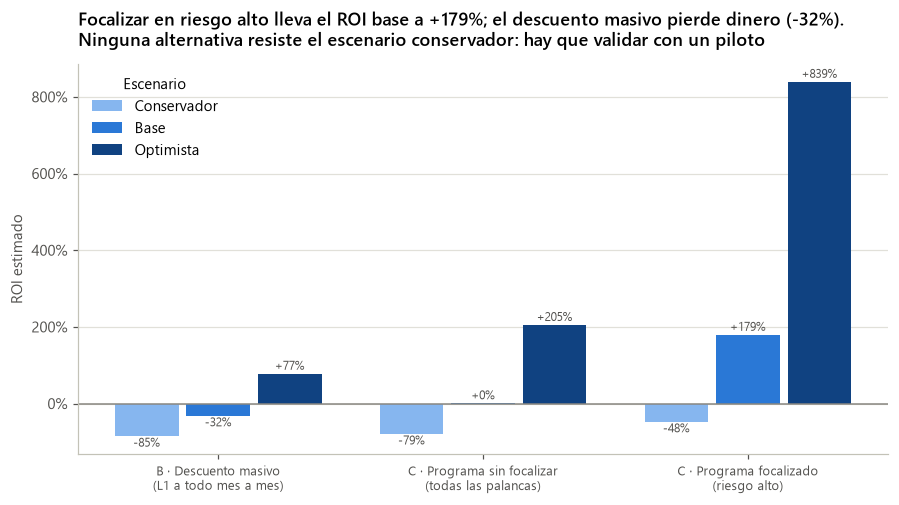

In [42]:
RAMPA_ESCENARIOS = {"Conservador": "#86b6ef", "Base": "#2a78d6", "Optimista": "#104281"}
fig, ax = plt.subplots(figsize=(9.5, 4.6))
nombres = list(ALTERNATIVAS)
ancho = 0.24
for j, esc in enumerate(ESCENARIOS):
    valores = resultados[resultados["escenario"] == esc].set_index("alternativa").loc[nombres, "roi"]
    pos = np.arange(len(nombres)) + (j - 1) * (ancho + 0.03)
    ax.bar(pos, valores, width=ancho, color=RAMPA_ESCENARIOS[esc], label=esc)
    for x_, v in zip(pos, valores):
        ax.text(x_, v + (0.04 if v >= 0 else -0.04), f"{v:+.0%}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8, color=TINTA_2)
ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(range(len(nombres)), [n.replace(" (", "\n(") for n in nombres], fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("ROI estimado")
ax.grid(axis="x", visible=False)
ax.legend(title="Escenario", loc="upper left")
roi_tabla = resultados.set_index(["alternativa", "escenario"])["roi"]
ax.set_title(f"Focalizar en riesgo alto lleva el ROI base a {roi_tabla[(nombres[2], 'Base')]:+.0%}; el descuento masivo pierde dinero ({roi_tabla[(nombres[0], 'Base')]:+.0%}).\n"
             "Ninguna alternativa resiste el escenario conservador: hay que validar con un piloto")
guardar(fig, "f08_roi_alternativas")

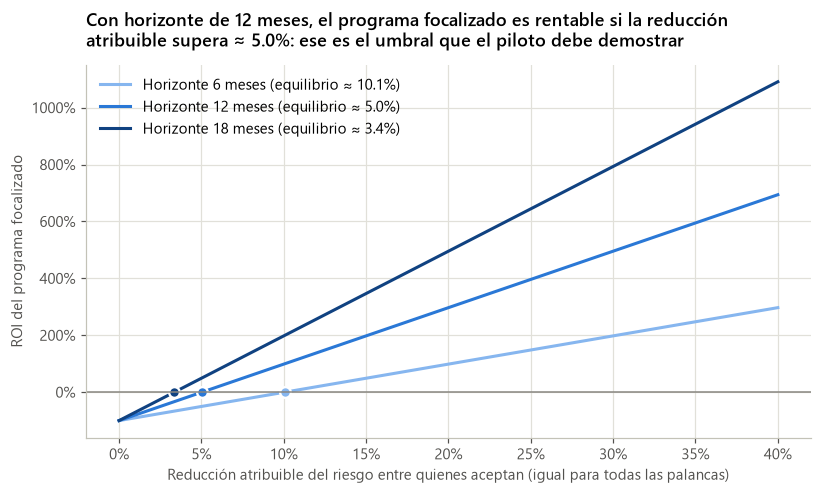

,reducción de equilibrio
6,10.1%
12,5.0%
18,3.4%


In [43]:
# 10.5 Sensibilidad: ROI del programa focalizado frente a la reducción atribuible (uniforme para todas las palancas)
def roi_con_reduccion(d, reduccion, horizonte):
    # ROI del escenario base cambiando solo la reducción atribuible y el horizonte (no modifica la tabla original)
    variante = supuestos.copy()
    mascara = variante["escenario"] == "Base"
    variante.loc[mascara, "reduccion"] = reduccion
    variante.loc[mascara, "horizonte_meses"] = horizonte
    return evaluar(d, "Base", variante)["roi"]


grilla = np.round(np.arange(0.0, 0.401, 0.005), 3)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
equilibrio = {}
for horizonte, color in [(6, "#86b6ef"), (12, AZUL), (18, "#104281")]:
    curva = np.array([roi_con_reduccion(focalizado, r_, horizonte) for r_ in grilla])
    # Punto de equilibrio: el ROI es lineal en la reducción, se interpola entre los dos puntos que cruzan cero
    k = int(np.argmax(curva >= 0))
    cruce = float(np.interp(0, curva[k - 1:k + 1], grilla[k - 1:k + 1]))
    equilibrio[horizonte] = cruce
    ax.plot(grilla, curva, color=color, lw=2, label=f"Horizonte {horizonte} meses (equilibrio ≈ {cruce:.1%})")
    ax.plot(cruce, 0, "o", color=color, ms=7, mec="white", mew=1.5)
ax.axhline(0, color=GRIS, lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Reducción atribuible del riesgo entre quienes aceptan (igual para todas las palancas)")
ax.set_ylabel("ROI del programa focalizado")
ax.legend(loc="upper left")
ax.set_title(f"Con horizonte de 12 meses, el programa focalizado es rentable si la reducción\natribuible supera ≈ {equilibrio[12]:.1%}: ese es el umbral que el piloto debe demostrar")
guardar(fig, "f09_sensibilidad_roi")
pd.Series(equilibrio, name="reducción de equilibrio").to_frame().style.format("{:.1%}")

### 10.6 Diseño del piloto A/B (Sesión 6)

| Componente | Diseño |
|---|---|
| Pregunta de negocio | ¿El programa focalizado reduce el churn de los clientes de riesgo alto lo suficiente para justificar su costo? |
| Hipótesis | Asignar a cada cliente de riesgo alto su palanca reduce su churn a 90 días frente a no intervenir, gracias a más valor percibido (protección), menos fricción (pago) y más acompañamiento (onboarding). |
| Población elegible | Clientes activos con score ≥ 40 % y palanca distinta de L0, en cada corte mensual. |
| Unidad de aleatorización | Cliente, asignado 50/50 a tratamiento o control, estratificado por palanca. |
| Métrica primaria | Tasa de churn a 90 días desde la asignación. |
| Secundarias | Aceptación de la oferta, adopción de protección, cambio a pago automático y migración de contrato. |
| Guardrails | ARPU (no caer más de 3 %), costo por cliente salvado, reclamos o tickets (requiere CRM). |
| Controles | Revisar *Sample Ratio Mismatch* (proporción observada vs. 50/50); no detener antes de la ventana; hipótesis registrada antes de ver resultados. |

In [44]:
Z_ALFA, Z_BETA = 1.959964, 0.841621  # alfa = 5 % bilateral, poder = 80 %


def n_por_brazo(p1, p2):
    p_barra = (p1 + p2) / 2
    return ((Z_ALFA * np.sqrt(2 * p_barra * (1 - p_barra)) + Z_BETA * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / (p1 - p2) ** 2


n_brazo = len(focalizado) // 2
p_control = focalizado["prob_churn"].mean()
efecto_base_abs = (focalizado["prob_churn"] * supuestos[supuestos["escenario"] == "Base"].set_index("palanca_id")
                   .reindex(focalizado["palanca_id"]).set_axis(focalizado.index).eval("aceptacion * reduccion")).mean()
mde_abs = (Z_ALFA + Z_BETA) * np.sqrt(2 * p_control * (1 - p_control) / n_brazo)
diseno_ab = pd.Series({
    "Clientes elegibles por corte": len(focalizado),
    "Clientes por brazo (50/50)": n_brazo,
    "Churn esperado en control": pct(p_control),
    "Efecto esperado (escenario base, pp)": f"{efecto_base_abs * 100:.1f} pp",
    "MDE con un solo corte (pp)": f"{mde_abs * 100:.1f} pp",
    "Clientes por brazo para detectar el efecto base": f"{n_por_brazo(p_control, p_control - efecto_base_abs):,.0f}",
    "Cortes mensuales a acumular (aprox.)": f"{np.ceil(n_por_brazo(p_control, p_control - efecto_base_abs) / n_brazo):.0f}",
})
diseno_ab.to_frame("Valor")

,Valor
Clientes elegibles por corte,820
Clientes por brazo (50/50),410
Churn esperado en control,55.9 %
"Efecto esperado (escenario base, pp)",3.4 pp
MDE con un solo corte (pp),9.7 pp
Clientes por brazo para detectar el efecto base,"3,305"
Cortes mensuales a acumular (aprox.),9


**Implicación del diseño.** Con un solo corte de esta muestra, el piloto solo detectaría efectos mucho mayores que el esperado en el escenario base. Por eso: (1) el piloto **acumula varias cohortes mensuales** de clientes de riesgo alto; (2) se monitorean **métricas líderes** con efectos más grandes y rápidos de detectar (aceptación, adopción de protección, cambio a pago automático); y (3) la base real de la operadora es mucho mayor que esta muestra de 7,043 clientes, así que el tamaño requerido se alcanzaría antes.

### 10.7 Lectura ejecutiva responsable

- **Lo que se observó:** 30.5 % del MRR se pierde por churn. La pérdida se concentra en clientes mes a mes con fibra y en los primeros meses de la relación.
- **El problema de atribución:** las diferencias de churn entre clientes con y sin protección, pago automático o contrato anual son **observacionales**. Quienes eligen esas opciones pueden ser distintos, así que los efectos de las palancas son supuestos acotados, no hechos.
- **Lo que no sabemos:** el efecto real de cada palanca, el costo real de servicio y la ventana exacta del churn (mes o trimestre).
- **Recomendación:** no escalar descuentos masivos (ROI negativo en los escenarios conservador y base). Lanzar el **programa focalizado en riesgo alto como piloto con grupo control**, empezando por las palancas de bajo costo (L4, L2 y L3), y escalar solo si la reducción atribuible observada supera el umbral de equilibrio.

## 11. Plan de monitoreo y acción (Plantilla 4)

In [45]:
mrr_alto = niveles_riesgo.loc["Alto", "mrr"]
roi_base_focal = roi_tabla[("C · Programa focalizado (riesgo alto)", "Base")]
plan_monitoreo = pd.DataFrame([
    ["% MRR retenido (North Star)", pct(KPI["pct_mrr_retenido"]), "≥ 75 %", f"≥ 75 %", f"{pct(KPI['pct_mrr_retenido'])} – 75 %", f"< {pct(KPI['pct_mrr_retenido'])}",
     "Proporción del ingreso recurrente que se conserva", "Rojo: el Comité revisa presupuesto y palancas. Amarillo: mantener el piloto y reforzar P1.", "Gerencia de Retención", "Mensual"],
    ["Tasa de churn", pct(KPI["tasa_churn"]), "≤ 22 %", "≤ 22 %", f"22 % – {pct(KPI['tasa_churn'])}", f"> {pct(KPI['tasa_churn'])}",
     "Clientes perdidos en el período", "Rojo: revisar qué segmento empeoró en la vista diagnóstica.", "Gerencia de Retención", "Mensual"],
    ["Churn temprano (0–6 m)", pct(KPI["churn_temprano_0_6"]), "≤ 45 %", "≤ 45 %", f"45 % – {pct(KPI['churn_temprano_0_6'])}", f"> {pct(KPI['churn_temprano_0_6'])}",
     "Calidad de la experiencia inicial", "Rojo: auditar el onboarding y ampliar la cobertura de L4.", "Customer Success", "Semanal"],
    ["% contratos a plazo", pct(KPI["pct_contrato_plazo"]), "≥ 50 %", "≥ 50 %", f"{pct(KPI['pct_contrato_plazo'])} – 50 %", f"< {pct(KPI['pct_contrato_plazo'])}",
     "Estabilidad de la base", "Rojo: revisar la oferta de migración (L1) solo en riesgo alto.", "Dirección Comercial", "Mensual"],
    ["% pago automático", pct(KPI["pct_pago_automatico"]), "≥ 50 %", "≥ 50 %", f"{pct(KPI['pct_pago_automatico'])} – 50 %", f"< {pct(KPI['pct_pago_automatico'])}",
     "Fricción de pago", "Rojo: reforzar el incentivo L3 y la comunicación en factura.", "Facturación", "Mensual"],
    ["Adopción de protección", pct(KPI["adopcion_proteccion"]), f"≥ {pct(KPI['adopcion_proteccion'] + 0.05)}", f"≥ {pct(KPI['adopcion_proteccion'] + 0.05)}",
     f"{pct(KPI['adopcion_proteccion'])} – {pct(KPI['adopcion_proteccion'] + 0.05)}", f"< {pct(KPI['adopcion_proteccion'])}",
     "Valor percibido del servicio de internet", "Rojo: revisar la oferta del bundle L2 en fibra.", "Producto / Marketing", "Mensual"],
    ["MRR activo en riesgo alto", usd(mrr_alto), f"≤ {usd(mrr_alto * 0.85)}", f"≤ {usd(mrr_alto * 0.85)}", f"{usd(mrr_alto * 0.85)} – {usd(mrr_alto * 1.10)}", f"> {usd(mrr_alto * 1.10)}",
     "Valor en juego en la lista de trabajo", "Rojo: priorizar contactos P1 en la semana y ampliar capacidad.", "Gerencia de Retención", "Semanal"],
    ["ARPU (balance)", usd(KPI["arpu"], 2), f"≥ {usd(KPI['arpu'] * 0.97, 2)}", f"≥ {usd(KPI['arpu'], 2)}", f"{usd(KPI['arpu'] * 0.97, 2)} – {usd(KPI['arpu'], 2)}", f"< {usd(KPI['arpu'] * 0.97, 2)}",
     "Que la retención no se compre con descuentos", "Rojo: suspender o limitar L1 (descuento).", "CFO", "Mensual"],
    ["ROI del programa (balance)", f"{roi_base_focal:+.0%} (estimado base)", "≥ 0 %", "≥ 0 %", "−20 % – 0 %", "< −20 %",
     "Retorno observado del piloto", "Verde: escalar. Amarillo: ajustar palancas. Rojo: detener y rediseñar.", "CFO / Gerencia de Retención", "Trimestral"],
    ["Uplift del piloto (churn 90 días)", "Sin medir", "Reducción ≥ umbral de equilibrio", "Significativo y ≥ equilibrio", "Positivo no significativo", "Nulo o negativo",
     "Efecto causal de las palancas", "Verde: escalar a toda la población elegible. Rojo: no escalar.", "Analítica (DataForge)", "A 30, 60 y 90 días"],
], columns=["Métrica", "Valor en el corte", "Meta", "Verde", "Amarillo", "Rojo", "Interpretación", "Acción sugerida", "Responsable", "Frecuencia"])
plan_monitoreo.to_csv(DIR_TAB / "plan_monitoreo.csv", index=False, encoding="utf-8-sig")
plan_monitoreo

,Métrica,Valor en el corte,Meta,Verde,Amarillo,Rojo,Interpretación,Acción sugerida,Responsable,Frecuencia
0,% MRR retenido (North Star),69.5 %,≥ 75 %,≥ 75 %,69.5 % – 75 %,< 69.5 %,Proporción del ingreso recurrente que se conserva,Rojo: el Comité revisa presupuesto y palancas....,Gerencia de Retención,Mensual
1,Tasa de churn,26.5 %,≤ 22 %,≤ 22 %,22 % – 26.5 %,> 26.5 %,Clientes perdidos en el período,Rojo: revisar qué segmento empeoró en la vista...,Gerencia de Retención,Mensual
2,Churn temprano (0–6 m),52.9 %,≤ 45 %,≤ 45 %,45 % – 52.9 %,> 52.9 %,Calidad de la experiencia inicial,Rojo: auditar el onboarding y ampliar la cober...,Customer Success,Semanal
3,% contratos a plazo,45.0 %,≥ 50 %,≥ 50 %,45.0 % – 50 %,< 45.0 %,Estabilidad de la base,Rojo: revisar la oferta de migración (L1) solo...,Dirección Comercial,Mensual
4,% pago automático,43.5 %,≥ 50 %,≥ 50 %,43.5 % – 50 %,< 43.5 %,Fricción de pago,Rojo: reforzar el incentivo L3 y la comunicaci...,Facturación,Mensual
5,Adopción de protección,53.7 %,≥ 58.7 %,≥ 58.7 %,53.7 % – 58.7 %,< 53.7 %,Valor percibido del servicio de internet,Rojo: revisar la oferta del bundle L2 en fibra.,Producto / Marketing,Mensual
6,MRR activo en riesgo alto,"USD 64,085","≤ USD 54,472","≤ USD 54,472","USD 54,472 – USD 70,493","> USD 70,493",Valor en juego en la lista de trabajo,Rojo: priorizar contactos P1 en la semana y am...,Gerencia de Retención,Semanal
7,ARPU (balance),USD 64.76,≥ USD 62.82,≥ USD 64.76,USD 62.82 – USD 64.76,< USD 62.82,Que la retención no se compre con descuentos,Rojo: suspender o limitar L1 (descuento).,CFO,Mensual
8,ROI del programa (balance),+179% (estimado base),≥ 0 %,≥ 0 %,−20 % – 0 %,< −20 %,Retorno observado del piloto,Verde: escalar. Amarillo: ajustar palancas. Ro...,CFO / Gerencia de Retención,Trimestral
9,Uplift del piloto (churn 90 días),Sin medir,Reducción ≥ umbral de equilibrio,Significativo y ≥ equilibrio,Positivo no significativo,Nulo o negativo,Efecto causal de las palancas,Verde: escalar a toda la población elegible. R...,Analítica (DataForge),"A 30, 60 y 90 días"


## 12. Exportación del modelo para Power BI

Se exporta un **modelo estrella** (Sesiones 3 y 8). `fact_clientes` es la tabla de hechos, con granularidad cliente-corte, y las dimensiones permiten filtrar en una sola dirección. Las tablas de supuestos, drivers, métricas y plan de monitoreo quedan **desconectadas**: las usan las medidas DAX y las páginas de acción y definiciones.

In [46]:
fact_clientes = df_analitico.merge(seg[["segmento", "segmento_id"]], on="segmento", how="left")
fact_clientes["proteccion_estado"] = np.select(
    [fact_clientes["tiene_internet"] == 0, fact_clientes["tiene_proteccion"] == 1], ["Sin internet", "Con seguridad o soporte"], default="Sin protección")
fact_clientes = fact_clientes[[
    "customer_id", "segmento_id", "antiguedad_meses", "contrato", "servicio_internet", "metodo_pago", "riesgo", "palanca_id",
    "genero", "adulto_mayor", "pareja", "dependientes", "facturacion_electronica", "telefonia", "lineas_multiples",
    "seguridad_online", "backup_online", "proteccion_equipo", "soporte_tecnico", "streaming_tv", "streaming_peliculas",
    "n_servicios_valor", "tiene_proteccion", "proteccion_estado", "tiene_internet", "pago_automatico", "contrato_plazo",
    "cargo_mensual", "cargo_total", "cargo_total_imputado", "churn", "estado_cliente", "mrr_perdido",
    "prob_churn", "mrr_riesgo_esperado", "registro_valido",
]].round({"prob_churn": 6, "mrr_riesgo_esperado": 4})

dim_antiguedad = pd.DataFrame({"antiguedad_meses": range(73)})
dim_antiguedad["banda_antiguedad"] = dim_antiguedad["antiguedad_meses"].map(banda_de)
dim_antiguedad["banda_orden"] = dim_antiguedad["banda_antiguedad"].map({b: i + 1 for i, b in enumerate(ORDEN_BANDAS)})
dim_antiguedad["etapa_ciclo_vida"] = dim_antiguedad["banda_antiguedad"].map(ETAPAS)
dim_antiguedad["etapa_orden"] = dim_antiguedad["etapa_ciclo_vida"].map({e: i + 1 for i, e in enumerate(ORDEN_ETAPAS)})

dim_contrato = pd.DataFrame({"contrato": ORDEN_CONTRATO, "contrato_orden": [1, 2, 3], "plazo_meses": [1, 12, 24], "es_plazo": [0, 1, 1]})
dim_internet = pd.DataFrame({"servicio_internet": ORDEN_INTERNET, "internet_orden": [1, 2, 3], "tiene_internet": [1, 1, 0]})
dim_pago = pd.DataFrame({"metodo_pago": ORDEN_PAGO, "pago_orden": [1, 2, 3, 4], "es_automatico": [0, 0, 1, 1]})
dim_riesgo = pd.DataFrame({"riesgo": ["Alto", "Medio", "Bajo", "No aplica (abandonó)"], "riesgo_orden": [1, 2, 3, 4],
                           "definicion": [f"Score ≥ {UMBRAL_ALTO:.0%}", f"Score entre {UMBRAL_MEDIO:.0%} y {UMBRAL_ALTO:.0%}", f"Score < {UMBRAL_MEDIO:.0%}", "Cliente que abandonó en el corte"]})
dim_segmento = seg[["segmento_id", "segmento", "contrato", "servicio_internet", "etapa_ciclo_vida", "prioridad", "palanca_dominante"]].copy()
dim_segmento["etapa_ciclo_vida"] = dim_segmento["etapa_ciclo_vida"].astype(str)
dim_segmento["prioridad_orden"] = dim_segmento["prioridad"].str[1].astype(int)
dim_segmento = dim_segmento.merge(PALANCAS[["palanca_id", "palanca", "responsable"]], left_on="palanca_dominante", right_on="palanca_id", how="left").drop(columns="palanca_id")
dim_escenario = pd.DataFrame({"escenario": list(ESCENARIOS), "escenario_orden": [1, 2, 3]})
drivers_pbi = drivers[["factor", "odds_ratio", "ic_inf", "ic_sup", "p_valor", "direccion"]].assign(orden=range(1, len(drivers) + 1))
dim_metricas = diccionario_metricas.copy()
dim_metricas["Valor en el corte"] = dim_metricas["Valor en el corte"].replace("Ver sección 10", usd(activos["mrr_riesgo_esperado"].sum()))
dim_metricas.insert(0, "orden", range(1, len(dim_metricas) + 1))

tablas_pbi = {
    "fact_clientes": fact_clientes, "dim_antiguedad": dim_antiguedad, "dim_contrato": dim_contrato, "dim_internet": dim_internet,
    "dim_pago": dim_pago, "dim_riesgo": dim_riesgo, "dim_palanca": PALANCAS, "dim_segmento": dim_segmento,
    "dim_escenario": dim_escenario, "supuestos_escenario": supuestos, "drivers_modelo": drivers_pbi,
    "dim_metricas": dim_metricas, "plan_monitoreo": plan_monitoreo.assign(orden=range(1, len(plan_monitoreo) + 1)),
}

# Integridad referencial del modelo estrella: llaves primarias únicas y todas las foráneas presentes en su dimensión
relaciones = [("antiguedad_meses", dim_antiguedad), ("contrato", dim_contrato), ("servicio_internet", dim_internet),
              ("metodo_pago", dim_pago), ("riesgo", dim_riesgo), ("palanca_id", PALANCAS), ("segmento_id", dim_segmento)]
for llave, dimension in relaciones:
    assert dimension[llave].is_unique, f"Llave duplicada en la dimensión de {llave}"
    assert fact_clientes[llave].isin(dimension[llave]).all(), f"Llave foránea huérfana: {llave}"
assert fact_clientes["customer_id"].is_unique and len(fact_clientes) == KPI["clientes"]

for nombre, tabla in tablas_pbi.items():
    tabla.to_csv(DIR_PBI / f"{nombre}.csv", index=False, encoding="utf-8")
print("✔ Modelo estrella exportado a", DIR_PBI.relative_to(ROOT))
pd.Series({n: t.shape for n, t in tablas_pbi.items()}).to_frame("(filas, columnas)")

✔ Modelo estrella exportado a powerbi\data


,"(filas, columnas)"
fact_clientes,"(7043, 36)"
dim_antiguedad,"(73, 5)"
dim_contrato,"(3, 4)"
dim_internet,"(3, 3)"
dim_pago,"(4, 3)"
dim_riesgo,"(4, 3)"
dim_palanca,"(6, 6)"
dim_segmento,"(26, 10)"
dim_escenario,"(3, 2)"
supuestos_escenario,"(12, 10)"


In [47]:
# Diccionario de métricas en Markdown (docs/) y cifras clave para el informe y la presentación
DIR_DOCS = ROOT / "docs"
DIR_DOCS.mkdir(exist_ok=True)
lineas = ["# Diccionario técnico de métricas — DataForge Consulting", "",
          "Generado por `notebooks/DataForge_Telco_Churn.ipynb` (sección 8.2). Valores calculados sobre el corte del dataset Telco Customer Churn (IBM).", ""]
for _, fila in dim_metricas.iterrows():
    lineas += [f"## {fila['orden']}. {fila['Nombre']}", "", "| Campo | Definición |", "|---|---|"]
    lineas += [f"| {campo} | {str(valor).replace('|', '/')} |" for campo, valor in fila.drop(["orden", "Nombre"]).items()]
    lineas.append("")
(DIR_DOCS / "diccionario_metricas.md").write_text("\n".join(lineas), encoding="utf-8")
dim_metricas.to_csv(DIR_TAB / "diccionario_metricas.csv", index=False, encoding="utf-8-sig")

foco_base = resultados.set_index(["alternativa", "escenario"])
cifras = {
    **{k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in KPI.items()},
    "auc_oof": float(AUC_OOF),
    "activos_riesgo_alto": int(niveles_riesgo.loc["Alto", "clientes"]),
    "mrr_activo_riesgo_alto": float(mrr_alto),
    "mrr_riesgo_esperado_total": float(activos["mrr_riesgo_esperado"].sum()),
    "mrr_riesgo_esperado_alto": float(niveles_riesgo.loc["Alto", "mrr_riesgo_esperado"]),
    "segmento_lider": lider["segmento"], "segmento_lider_part_mrr_perdido": float(lider["participacion_mrr_perdido"]),
    "segmento_lider_part_clientes": float(lider["participacion_clientes"]),
    "roi": {f"{alt} | {esc}": float(foco_base.loc[(alt, esc), "roi"]) for alt in ALTERNATIVAS for esc in ESCENARIOS},
    "reduccion_equilibrio_12m": float(equilibrio[12]),
    "piloto": {k: str(v) for k, v in diseno_ab.items()},
}
(ROOT / "outputs" / "cifras_clave.json").write_text(json.dumps(cifras, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(cifras, ensure_ascii=False, indent=2)[:1500])

{
  "clientes": 7043,
  "clientes_activos": 5174,
  "churners": 1869,
  "tasa_churn": 0.2653698707936959,
  "mrr_total": 456116.6,
  "mrr_perdido": 139130.84999999998,
  "pct_mrr_perdido": 0.3050335155528213,
  "pct_mrr_retenido": 0.6949664844471787,
  "arpu": 64.76169246059918,
  "arpu_churners": 74.44133226324236,
  "arpu_activos": 61.26512369540008,
  "churn_temprano_0_6": 0.5293720459149224,
  "pct_contrato_plazo": 0.4498083203180463,
  "pct_pago_automatico": 0.4353258554593213,
  "adopcion_proteccion": 0.5372485046220772,
  "auc_oof": 0.8460185853331356,
  "activos_riesgo_alto": 820,
  "mrr_activo_riesgo_alto": 64084.7,
  "mrr_riesgo_esperado_total": 68096.46887628507,
  "mrr_riesgo_esperado_alto": 35999.53359117291,
  "segmento_lider": "Mes a mes · Fibra óptica",
  "segmento_lider_part_mrr_perdido": 0.7222122196479069,
  "segmento_lider_part_clientes": 0.30214397273888965,
  "roi": {
    "B · Descuento masivo (L1 a todo mes a mes) | Conservador": -0.8506062151054413,
    "B · Des

## 13. Reflexión final

**Métricas que ya se pueden calcular con confianza:** clientes, tasa de churn del corte, MRR, MRR perdido, % MRR retenido, ARPU, % de contratos a plazo, % de pago automático, adopción de protección y churn por segmento y por antigüedad. Todas reconcilian con el archivo crudo y se calculan como razones de sumas.

**Métricas calculables, pero con advertencias:**

- **La tasa de churn y la pérdida absoluta** son del *período de corte*. El churn está sobrerrepresentado, así que no se anualizan.
- **El análisis por antigüedad** describe cohortes condicionales con sesgo de supervivencia.
- **El score de riesgo y el MRR en riesgo esperado** sirven para ordenar, no como pronóstico.
- **El ROI** depende de supuestos explícitos de aceptación, efecto, margen y horizonte.

**Métricas que todavía no se pueden calcular y datos que faltan:**

| Métrica | Dato faltante |
|---|---|
| Tendencia mensual de KPIs, retención por cohorte de alta y estacionalidad | Cortes mensuales con `fecha_corte` y fecha de alta |
| ROI real y costo por cliente salvado | Costos de servicio, incentivos y contacto |
| Uplift causal de las palancas | Piloto con grupo control |
| Satisfacción y causas de abandono | Encuestas, NPS, tickets y motivo de baja |
| Cobertura de contacto y aceptación | CRM de campañas de retención |

**El problema de calidad que más puede afectar el dashboard** no es un nulo ni un duplicado. Es la **ambigüedad de la ventana de churn** combinada con la **ausencia de fechas**: un tablero que mostrara 26.5 % como churn mensual induciría decisiones equivocadas. Por eso las métricas del dashboard dicen explícitamente "período de corte".

**Aprendizaje.** La tabla cruda ya venía casi limpia, pero no era una tabla analítica. Convertirla en evidencia para decidir exigió definir la unidad de análisis, homologar las categorías estructurales, crear las banderas que alimentan los KPIs, validar reglas de negocio (incluida la plausibilidad de la propia tasa de churn) y documentar qué se puede y qué no se puede concluir.